wrote pt_figures/PT_master_curve_combined.pdf and pt_figures/PT_master_curve_combined.png


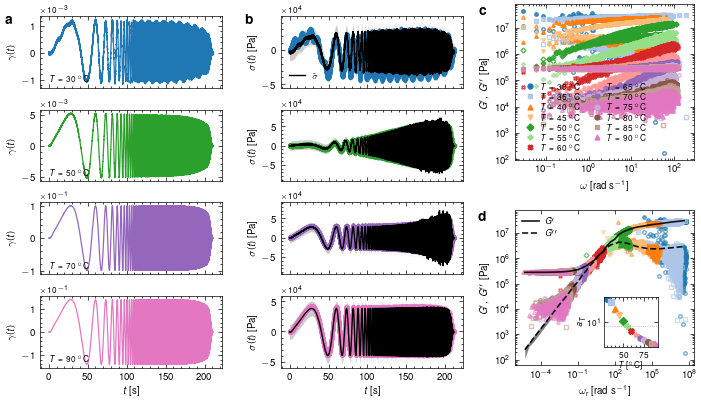

In [10]:
"""
plot_master_curve_standalone_combined.py
=========================================
Three-column master-curve figure, built ONLY from the files written by
`export_master_curve()` (a `<path>.npz` + `<path>.json` pair). No import
of `paper_utils`, `rheogp`, or `torch` anywhere in this file -- copy it
next to your exported data on any machine that has numpy + matplotlib
(+ optionally `scienceplots`) and run it.

This is the COMBINED variant: storage (G') and loss (G'') share ONE
panel in column 3's top half (filled markers = G', open markers = G''),
instead of getting split into separate panels. See
plot_master_curve_standalone_split.py for the two-panel version.

Layout
------
    col 1                 col 2                  col 3
    strain gamma(t)       stress sigma(t)         (top)    unshifted FFT
    one row per T shown   measured + predicted             spectrum, all T
    ...                   ...                     (bottom) shifted FFT +
                                                             GPR analytic
                                                             master curve
                                                             + posterior-
                                                             predictive FFT
                                                             ensemble band,
                                                             with an inset
                                                             of a_T vs T

Only a representative subset of temperatures is drawn in columns 1-2
(set N_SHOW below); column 3 uses every record, since the point of that
panel is the TTS collapse itself. Every temperature gets its own fixed
(color, marker) pair, used consistently across every panel of the
figure (including the measured-stress markers in column 2, which share
the strain color for that row -- only the model's prediction stays
black), listed once in a legend -- no colorbar. Each strain/stress
row's y-axis carries its own independent x10^n offset notation, since
one row's stress range can be orders of magnitude away from the next.

Column 3 is built as its OWN nested grid spanning the full column
height (`outer[:, 2]`), independent of the row indices columns 1-2 use
-- NOT sliced by row range (`outer[0:n_top, 2]` / `outer[n_top:, 2]`)
like an earlier version of this script did. Tying column 3's internal
split to the same row boundaries as columns 1-2 forces
`constrained_layout` to reconcile column 3's spacing needs at that
specific row boundary across EVERY column, which showed up as a
visibly bigger gap between two of the strain/stress rows even though
those rows didn't need the extra space themselves. Nesting a nested
GridSpecFromSubplotSpec inside a single spanning cell avoids that
forced cross-column alignment entirely.

The master-curve panel can show either or both of two DIFFERENT
uncertainty estimates -- pick with the single `MASTER_CURVE_SOURCE`
setting below ("analytic", "posterior", or "both"):
  * the analytic Gstar curve+band (from `_model_curve_from_mj` in
    paper_utils.py) -- a credible interval on the *mean* prefactor,
    which shrinks as more data is pooled and can look implausibly tight
    next to noisy raw data;
  * the posterior-predictive FFT ensemble curve+band (from
    `_posterior_fft_ensemble`, `postfft_*` arrays) -- built by drawing
    correlated posterior samples of the fitted stress trace and
    FFT-transforming each one, so its spread reflects the model's
    actual predictive uncertainty in the frequency domain.
They are not the same quantity, so "both" is the default for
comparison, but either can be selected on its own.

Edit the "USER SETTINGS" block below and run:  python3 plot_master_curve_standalone_combined.py
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ----------------------------------------------------------------
# USER SETTINGS
# ----------------------------------------------------------------
# Where the fitting notebook (and run_broadband_demo.py) wrote their
# outputs. Every input below is read from this one folder; figures
# this cell writes go to FIG_DIR.
DATA_DIR = "pt_fzm_out"
EXPORT_PATH = f"{DATA_DIR}/PT_export_fzm"      # base path -> reads fmm_export.npz + fmm_export.json
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "pt_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/PT_master_curve_combined"  # writes <OUT_NAME>.pdf and <OUT_NAME>.png next to this script
N_SHOW = 4                      # how many temperatures to draw in columns 1-2
SHOW_PREDICTED_BAND = True      # +/- 2 sigma band on the predicted stress
SHOW_TRUTH_SHIFT_FACTORS = True # overlay shift_factors_truth in the inset, if present

# Which master-curve estimate(s) to draw in the bottom spectrum panel,
# each with its own credible band -- the single switch for what used to
# be two independent flags:
#   "analytic"  -- only the analytic Gstar curve (tight: a CI on the mean
#                  prefactor, from _model_curve_from_mj in paper_utils.py)
#   "posterior" -- only the posterior-predictive FFT ensemble (wider:
#                  reflects actual predictive uncertainty, from
#                  _posterior_fft_ensemble / postfft_* arrays)
#   "both"      -- draw both, clearly labeled, for comparison
MASTER_CURVE_SOURCE = "posterior"
N_FREQ_BINS = 40                # log-spaced bins used to summarize the FFT ensemble

# Column-3 internal proportions: [combined spectrum row, master-curve row]
COL3_HEIGHT_RATIOS = [1.0, 1.0]


# ----------------------------------------------------------------
# Inline reload of an export_master_curve() bundle -- pure numpy + json,
# duplicated here on purpose so this script has zero local imports.
# ----------------------------------------------------------------
def load_export(path):
    from types import SimpleNamespace

    with open(f"{path}.json") as fh:
        meta = json.load(fh)
    data = np.load(f"{path}.npz")
    arrays = {k: data[k] for k in data.files}

    def record(i):
        pfx = f"rec{i}_"
        return {k[len(pfx):]: v for k, v in arrays.items() if k.startswith(pfx)}

    model_curve = None
    if "model_curve_omega" in arrays:
        model_curve = (
            arrays["model_curve_omega"], arrays["model_curve_Gp"],
            arrays["model_curve_Gdp"], arrays.get("model_curve_Gp_ci"),
            arrays.get("model_curve_Gdp_ci"),
        )

    return SimpleNamespace(meta=meta, arrays=arrays, record=record,
                            n_records=meta["n_records"], model_curve=model_curve)


# ----------------------------------------------------------------
# Style (matches the paper's other figures)
# ----------------------------------------------------------------
try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})

TAB10 = plt.cm.tab20.colors  # discrete colors, cycled per record
MARKERS = ["o", "s", "^", "v", "D", "P", "X", "*", "h", "8"]  # cycled per record
COLOR_PRED = "black"       # predicted stress line + band -- stays fixed, not per-record
COLOR_MASTER = "k"         # analytic + ensemble master-curve lines
COLOR_ANALYTIC_BAND = "0.6"     # analytic Gstar credible band (gray)
COLOR_POSTFFT_BAND = "tab:orange"  # posterior-predictive FFT ensemble band


def add_panel_letter(ax, text, xoff=-20, yoff=0, fontsize=10):
    """Bold panel letter just outside the top-left of an axes, offset in
    POINTS (not axes-fraction) so it stays put regardless of that
    panel's own size -- same convention/size as the paper's other
    multi-panel figures."""
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


def record_style(i):
    """Fixed (color, marker) pair per record index -- same identity in
    every panel of the figure, so a color+marker combo always means the
    same temperature no matter which column you're looking at."""
    return TAB10[i % len(TAB10)], MARKERS[i % len(MARKERS)]


def use_sci_y(ax, fontsize=6):
    """Force a scientific-notation x10^n offset on this axis's own y
    ticks (independent of any other axis), so a row with values ~1e-2
    doesn't render long decimal tick labels next to a row with ~1e3."""
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(fontsize)


def summarize_ensemble(omega, values, n_bins=40):
    """Bin a (possibly huge) scatter cloud of (omega, value) points from
    the posterior-predictive FFT ensemble into log-spaced frequency bins
    and return the per-bin median + 95% interval. Returns None if there
    is nothing usable to summarize."""
    omega = np.asarray(omega, float)
    values = np.asarray(values, float)
    valid = np.isfinite(omega) & (omega > 0) & np.isfinite(values)
    omega, values = omega[valid], values[valid]
    if omega.size < 5:
        return None
    edges = np.logspace(np.log10(omega.min()), np.log10(omega.max()), n_bins + 1)
    centers = np.sqrt(edges[:-1] * edges[1:])
    med = np.full(n_bins, np.nan)
    lo = np.full(n_bins, np.nan)
    hi = np.full(n_bins, np.nan)
    idx = np.clip(np.digitize(omega, edges) - 1, 0, n_bins - 1)
    for b in range(n_bins):
        sel = values[idx == b]
        if sel.size >= 5:
            med[b] = np.median(sel)
            lo[b] = np.quantile(sel, 0.025)
            hi[b] = np.quantile(sel, 0.975)
    keep = np.isfinite(med)
    if not keep.any():
        return None
    return centers[keep], med[keep], lo[keep], hi[keep]


# ----------------------------------------------------------------
# Load data
# ----------------------------------------------------------------
data = load_export(EXPORT_PATH)
T = np.asarray(data.arrays["temperatures"], float)
n_rec = data.n_records

# a representative, evenly spaced subset of temperatures for columns 1-2
n_show = min(N_SHOW, n_rec)
show_idx = np.unique(np.round(np.linspace(0, n_rec - 1, n_show)).astype(int))
n_show = len(show_idx)

i_ref = int(data.meta.get("i_ref", 0))

# ----------------------------------------------------------------
# Figure / GridSpec: n_show rows for cols 1-2. Column 3 is ONE spanning
# cell (outer[:, 2]) subdivided independently -- see the module
# docstring for why this avoids a forced cross-column spacing conflict.
# ----------------------------------------------------------------
fig = plt.figure(figsize=(7.0, 4))
outer = gridspec.GridSpec(n_show, 3, figure=fig, width_ratios=[1.0, 1.0, 1.25],
                           wspace=0.1, hspace=0.06)

gs_col3 = gridspec.GridSpecFromSubplotSpec(
    2, 1, subplot_spec=outer[:, 2], height_ratios=COL3_HEIGHT_RATIOS, hspace=0.1)
ax_spec_top = fig.add_subplot(gs_col3[0])  # combined storage+loss spectrum, unshifted
ax_spec_bot = fig.add_subplot(gs_col3[1])  # shifted spectra + master curve

# ----------------------------------------------------------------
# Columns 1-2: strain and stress vs time, one row per selected temperature
# ----------------------------------------------------------------
ax_strain0 = None
ax_stress0 = None
for row, i in enumerate(show_idx):
    rec = data.record(int(i))
    Ti = T[i]
    c, mk = record_style(int(i))

    ax_g = fig.add_subplot(outer[row, 0], sharex=ax_strain0)
    ax_s = fig.add_subplot(outer[row, 1], sharex=ax_stress0)
    if ax_strain0 is None:
        ax_strain0, ax_stress0 = ax_g, ax_s

    ax_g.plot(rec["t"], rec["gamma"], color=c, lw=0.9)
    ax_g.set_ylabel(r"$\gamma(t)$")
    ax_g.text(0.05, 0.06, f"$T={Ti:g}~^\circ\mathrm{{C}}$", transform=ax_g.transAxes,
              fontsize=6, ha="left", va="bottom", color="black")
    use_sci_y(ax_g)

    # measured stress follows the same per-record color as strain;
    # the model's prediction stays black regardless of temperature.
    ax_s.plot(rec["t"], rec["sigma"], color=c, lw=0.0,
              marker="o", ms=1.6, alpha=0.6)
    ax_s.plot(rec["t"], rec["pred"], color=COLOR_PRED, lw=1.0,
              label=r"$\bar{\sigma}$" if row == 0 else None)
    if SHOW_PREDICTED_BAND and "pred_std" in rec:
        ax_s.fill_between(rec["t"], rec["pred"] - 2 * rec["pred_std"],
                          rec["pred"] + 2 * rec["pred_std"],
                          color=COLOR_PRED, alpha=0.20, lw=0)
    ax_s.set_ylabel(r"$\sigma(t)$ [Pa]")
    use_sci_y(ax_s)

    if row == n_show - 1:
        ax_g.set_xlabel(r"$t$ [s]")
        ax_s.set_xlabel(r"$t$ [s]")
    else:
        plt.setp(ax_g.get_xticklabels(), visible=False)
        plt.setp(ax_s.get_xticklabels(), visible=False)

    if row == 0:
        add_panel_letter(ax_g, r"$\mathbf{a}$", yoff=2)
        add_panel_letter(ax_s, r"$\mathbf{b}$", yoff=2)

ax_stress0.legend(frameon=False, loc="best")

# ----------------------------------------------------------------
# Column 3, top: unshifted FFT spectra, storage (G') and loss (G'')
# overlaid in ONE panel -- filled markers = G', open markers = G''
# ----------------------------------------------------------------
for i in range(n_rec):
    rec = data.record(i)
    c, mk = record_style(i)
    ax_spec_top.loglog(rec["fft_omega"], rec["fft_Gp"], marker=mk, ms=2.5,
                       ls="none", mfc=c, mec=c, alpha=0.8)
    ax_spec_top.loglog(rec["fft_omega"], rec["fft_Gdp"], marker=mk, ms=2.5,
                       ls="none", mfc="none", mec=c, alpha=0.8)
ax_spec_top.set_ylabel(r"$G',\,G''$ [Pa]")
ax_spec_top.set_xlabel(r"$\omega~[\mathrm{rad~s}^{-1}]$")
add_panel_letter(ax_spec_top, r"$\mathbf{c}$")

temp_handles = [plt.Line2D([], [], marker=record_style(i)[1], ls="none",
                           mfc=record_style(i)[0], mec=record_style(i)[0], ms=3.5,
                           label=f"$T={T[i]:g}~^\circ\mathrm{{C}}$")
               for i in range(n_rec)]
ax_spec_top.legend(handles=temp_handles, frameon=False, loc="best",
                   ncol=1 if n_rec <= 6 else 2,
                   columnspacing=0.8, handletextpad=0.3, labelspacing=0.3)

# ----------------------------------------------------------------
# Column 3, bottom: shifted FFT spectra + analytic master curve +
# posterior-predictive FFT ensemble band
# ----------------------------------------------------------------
for i in range(n_rec):
    rec = data.record(i)
    c, mk = record_style(i)
    ax_spec_bot.loglog(rec["fft_omega_reduced"], rec["fft_Gp"], marker=mk, ms=2.5,
                       ls="none", mfc=c, mec=c, alpha=0.6)
    ax_spec_bot.loglog(rec["fft_omega_reduced"], rec["fft_Gdp"], marker=mk, ms=2.5,
                       ls="none", mfc="none", mec=c, alpha=0.6)

handles, labels = [], []


def _valid_band(ci):
    # ci is None if it was never exported; NaN-filled if every posterior
    # draw produced a non-finite/non-positive prefactor (bad fit) -- in
    # both cases fill_between would silently draw nothing, so check
    # explicitly rather than let the band vanish without a trace.
    return ci is not None and np.any(np.isfinite(ci))


show_posterior = MASTER_CURVE_SOURCE in ("posterior", "both")
show_analytic = MASTER_CURVE_SOURCE in ("analytic", "both")

# -- posterior-predictive FFT ensemble: median + band together (wider,
#    reflects actual predictive uncertainty rather than uncertainty in
#    the mean prefactor). Solid = G', dashed = G'' -- both get a legend
#    entry (\bar{G'}/\bar{G''}, the "posterior mean" notation), handles
#    and labels appended IN LOCKSTEP so a later "both" run doesn't
#    silently shift every subsequent label by one slot (ax.legend(handles,
#    labels) zips to the SHORTER list with no warning if they go out of
#    sync).
if show_posterior and "postfft_omega_reduced" in data.arrays \
        and data.arrays["postfft_omega_reduced"].size:
    pf_omega = data.arrays["postfft_omega_reduced"]
    for name, values, ls, bar_label in (
            ("$G'$", data.arrays["postfft_Gp"], "-", r"$\bar{G'}$"),
            ("$G''$", data.arrays["postfft_Gdp"], "--", r"$\bar{G''}$")):
        summary = summarize_ensemble(pf_omega, values, n_bins=N_FREQ_BINS)
        if summary is None:
            print(f"  (posterior-FFT ensemble for {name}: not enough points to bin)")
            continue
        centers, med, lo, hi = summary
        ax_spec_bot.fill_between(centers, lo, hi, color="k",
                                 alpha=0.5, lw=0)
        h_med, = ax_spec_bot.loglog(centers, med, color="k", lw=1.2, ls=ls, alpha=0.9)
        handles.append(h_med)
        labels.append(bar_label)
elif show_posterior:
    print("  (no posterior-predictive FFT ensemble in this export -- "
          "postfft_omega_reduced not found; re-export with include_posterior_fft=True)")

# -- analytic Gstar: median + band together (tight: a CI on the mean prefactor)
if show_analytic and data.model_curve is not None:
    omega_m, Gp_m, Gdp_m, Gp_ci, Gdp_ci = data.model_curve
    h_gp, = ax_spec_bot.loglog(omega_m, Gp_m, color=COLOR_MASTER, lw=1.2, ls="-")
    h_gdp, = ax_spec_bot.loglog(omega_m, Gdp_m, color=COLOR_MASTER, lw=1.2, ls="--")
    handles += [h_gp, h_gdp]
    labels += ["GPR $G'$ (analytic)", "GPR $G''$ (analytic)"]

    band_drawn = False
    if _valid_band(Gp_ci):
        ax_spec_bot.fill_between(omega_m, Gp_ci[0], Gp_ci[1], color=COLOR_ANALYTIC_BAND,
                                 alpha=0.35, lw=0)
        band_drawn = True
    else:
        print("  (no G' credible band: Gp_ci missing or all-NaN in the export)")
    if _valid_band(Gdp_ci):
        ax_spec_bot.fill_between(omega_m, Gdp_ci[0], Gdp_ci[1], color=COLOR_ANALYTIC_BAND,
                                 alpha=0.20, lw=0)
        band_drawn = True
    else:
        print("  (no G'' credible band: Gdp_ci missing or all-NaN in the export)")
    if band_drawn:
        handles.append(plt.matplotlib.patches.Patch(facecolor=COLOR_ANALYTIC_BAND, alpha=0.35, lw=0))
        labels.append("mean-prefactor 95\\% CI")
elif show_analytic:
    print("  (no analytic master curve in this export -- model_curve_omega not found)")

if handles:
    ax_spec_bot.legend(handles, labels, frameon=False, loc="best", fontsize=6)

ax_spec_bot.set_ylabel(r"$G',\,G''$ [Pa]")
ax_spec_bot.set_xlabel(r"$\omega_{\mathrm{r}}~[\mathrm{rad~s}^{-1}]$")
add_panel_letter(ax_spec_bot, r"$\mathbf{d}$")

# inset: shift factors vs temperature, same per-record color/marker identity
# lower-center: the open region between the high-T G'' cloud (left)
# and the low-T G'' tail (right edge)
ax_inset = ax_spec_bot.inset_axes([0.50, 0.12, 0.30, 0.32]) # x, y, w, h
for i in range(n_rec):
    c, mk = record_style(i)
    ax_inset.plot(T[i], data.arrays["shift_factors"][i], marker=mk, ms=4,
                 ls="none", mfc=c, mec=c)
if SHOW_TRUTH_SHIFT_FACTORS and "shift_factors_truth" in data.arrays:
    ax_inset.plot(T, data.arrays["shift_factors_truth"], "-",
                 color="0.3", label="truth")
    #ax_inset.legend(frameon=False, fontsize=6, loc="best")
ax_inset.axhline(1.0, color="0.6", lw=0.5, ls=":")
ax_inset.set_yscale("log")
ax_inset.set_xlabel(r"$T~[^\circ\mathrm{C}]$", fontsize=6, labelpad=1)
ax_inset.set_ylabel("$a_T$", fontsize=6, labelpad=1)
ax_inset.tick_params(labelsize=6)

# ----------------------------------------------------------------
fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")

wrote pt_figures/PT_master_curve_split.pdf and pt_figures/PT_master_curve_split.png
n_records = 13, N (total pooled samples) = 275150


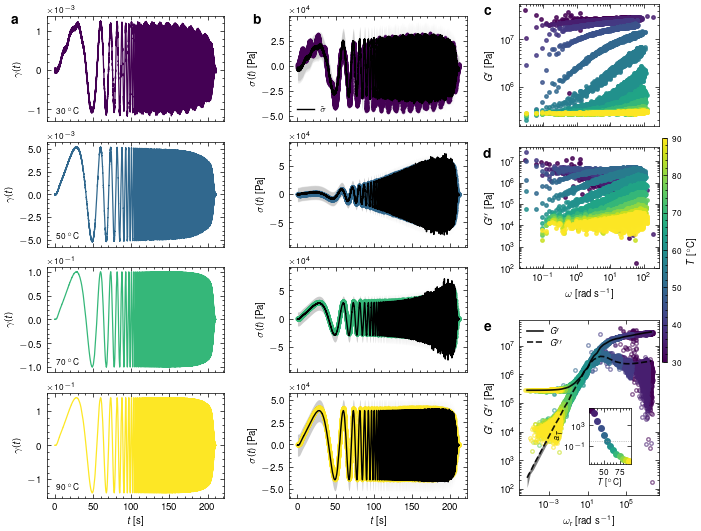

In [19]:
"""
plot_master_curve_standalone_combined.py
=========================================
Three-column master-curve figure, built ONLY from the files written by
`export_master_curve()` (a `<path>.npz` + `<path>.json` pair). No import
of `paper_utils`, `rheogp`, or `torch` anywhere in this file -- copy it
next to your exported data on any machine that has numpy + matplotlib
(+ optionally `scienceplots`) and run it.

This is the COMBINED variant: storage (G') and loss (G'') share ONE
panel in column 3's top half (filled markers = G', open markers = G''),
instead of getting split into separate panels. See
plot_master_curve_standalone_split.py for the two-panel version.

Layout
------
    col 1                 col 2                  col 3
    strain gamma(t)       stress sigma(t)         (c) unshifted G' vs omega
    one row per T shown   measured + predicted     (d) unshifted G'' vs omega
    ...                   ...                      (e) shifted FFT +
                                                         GPR analytic
                                                         master curve
                                                         + posterior-
                                                         predictive FFT
                                                         ensemble band,
                                                         with an inset
                                                         of a_T vs T

Only a representative subset of temperatures is drawn in columns 1-2
(set N_SHOW below); column 3 uses every record, since the point of that
panel is the TTS collapse itself. Temperature is a continuous quantity,
so it is encoded as ONE sequential colormap (light->dark, set via
TEMP_CMAP below) rather than a cycled categorical palette -- every
record's color comes from its own T value through that same colormap,
used consistently across every panel (including the measured-stress
markers in column 2, which share the strain color for that row -- only
the model's prediction stays black). A single shared colorbar next to
column 3 replaces what used to be a >10-entry marker+color legend.
Storage and loss moduli get their OWN stacked panels (c, d) in the
unshifted spectrum rather than one overlaid panel with filled/open
markers -- with 13 overlapping temperature series, filled vs. open
circles on top of each other was too dense to read even with distinct
colors; splitting by quantity instead of overlaying them trades one
compact panel for two legible ones. Each strain/stress row's y-axis
carries its own independent x10^n offset notation, since one row's
stress range can be orders of magnitude away from the next.

Column 3 is built as its OWN nested grid spanning the full column
height (`outer[:, 2]`), independent of the row indices columns 1-2 use
-- NOT sliced by row range (`outer[0:n_top, 2]` / `outer[n_top:, 2]`)
like an earlier version of this script did. Tying column 3's internal
split to the same row boundaries as columns 1-2 forces
`constrained_layout` to reconcile column 3's spacing needs at that
specific row boundary across EVERY column, which showed up as a
visibly bigger gap between two of the strain/stress rows even though
those rows didn't need the extra space themselves. Nesting a nested
GridSpecFromSubplotSpec inside a single spanning cell avoids that
forced cross-column alignment entirely.

The master-curve panel can show either or both of two DIFFERENT
uncertainty estimates -- pick with the single `MASTER_CURVE_SOURCE`
setting below ("analytic", "posterior", or "both"):

  * the analytic Gstar curve+band (from `_model_curve_from_mj` in
    paper_utils.py) -- a credible interval on the *mean* prefactor,
    which shrinks as more data is pooled and can look implausibly tight
    next to noisy raw data;
  * the posterior-predictive FFT ensemble curve+band (from
    `_posterior_fft_ensemble`, `postfft_*` arrays) -- built by drawing
    correlated posterior samples of the fitted stress trace and
    FFT-transforming each one, so its spread reflects the model's
    actual predictive uncertainty in the frequency domain.

They are not the same quantity, so "both" is the default for
comparison, but either can be selected on its own.

Edit the "USER SETTINGS" block below and run:  python3 plot_master_curve_standalone_combined.py
"""
import os
import json

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize

# ----------------------------------------------------------------
# USER SETTINGS
# ----------------------------------------------------------------
# Where the fitting notebook (and run_broadband_demo.py) wrote their
# outputs. Every input below is read from this one folder; figures
# this cell writes go to FIG_DIR.
DATA_DIR = "pt_fzm_out"
EXPORT_PATH = f"{DATA_DIR}/PT_export_fzm"      # base path -> reads fmm_export.npz + fmm_export.json
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "pt_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/PT_master_curve_split"  # writes <OUT_NAME>.pdf and <OUT_NAME>.png next to this script
N_SHOW = 4                      # how many temperatures to draw in columns 1-2
SHOW_PREDICTED_BAND = True      # +/- 2 sigma band on the predicted stress
SHOW_TRUTH_SHIFT_FACTORS = True # overlay shift_factors_truth in the inset, if present

# Which master-curve estimate(s) to draw in the bottom spectrum panel,
# each with its own credible band -- the single switch for what used to
# be two independent flags:
#   "analytic"  -- only the analytic Gstar curve (tight: a CI on the mean
#                  prefactor, from _model_curve_from_mj in paper_utils.py)
#   "posterior" -- only the posterior-predictive FFT ensemble (wider:
#                  reflects actual predictive uncertainty, from
#                  _posterior_fft_ensemble / postfft_* arrays)
#   "both"      -- draw both, clearly labeled, for comparison
MASTER_CURVE_SOURCE = "posterior"
N_FREQ_BINS = 40                # log-spaced bins used to summarize the FFT ensemble

# Column-3 internal proportions: [G' row, G'' row, master-curve row]
COL3_HEIGHT_RATIOS = [0.9, 0.9, 1.3]

# Overall figure size -- bumped taller than a 2-row column 3 needed,
# since column 3 now stacks three panels instead of two.
FIG_SIZE = (7.0, 5.3)

# Temperature is continuous, so it gets ONE sequential colormap
# (light -> dark) instead of a cycled categorical palette. "viridis" is
# perceptually uniform and colorblind-safe out of the box; "plasma",
# "magma", "cividis" are equally safe drop-in swaps.
TEMP_CMAP = "viridis"

# Shift-factor inset placement/size, in ax_spec_bot axes-fraction
# coordinates: [x, y, width, height]. Lower-center is the one open
# region of this material's master-curve panel: the low-T G'' tail runs
# down the right edge and the high-T G'' cloud sits lower-left. The
# Gbar'/Gbar'' legend is pinned upper-left below. Lifted off y=0.08 so
# it clears the panel's own x-axis tick labels underneath.
INSET_BBOX = [0.50, 0.18, 0.30, 0.32]


# ----------------------------------------------------------------
# Inline reload of an export_master_curve() bundle -- pure numpy + json,
# duplicated here on purpose so this script has zero local imports.
# ----------------------------------------------------------------
def load_export(path):
    from types import SimpleNamespace

    with open(f"{path}.json") as fh:
        meta = json.load(fh)
    data = np.load(f"{path}.npz")
    arrays = {k: data[k] for k in data.files}

    def record(i):
        pfx = f"rec{i}_"
        return {k[len(pfx):]: v for k, v in arrays.items() if k.startswith(pfx)}

    model_curve = None
    if "model_curve_omega" in arrays:
        model_curve = (
            arrays["model_curve_omega"], arrays["model_curve_Gp"],
            arrays["model_curve_Gdp"], arrays.get("model_curve_Gp_ci"),
            arrays.get("model_curve_Gdp_ci"),
        )
    return SimpleNamespace(meta=meta, arrays=arrays, record=record,
                            n_records=meta["n_records"], model_curve=model_curve)


# ----------------------------------------------------------------
# Style (matches the paper's other figures)
# ----------------------------------------------------------------
try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})

REC_MARKER = "o"            # single fixed marker everywhere; filled vs open
                             # (mfc=color vs mfc="none") carries G' vs G''.
                             # Marker shape no longer needs to carry
                             # temperature identity now that color does
                             # that continuously -- see record_color().
COLOR_PRED = "black"        # predicted stress line + band -- stays fixed, not per-record
COLOR_MASTER = "k"          # analytic + ensemble master-curve lines
COLOR_ANALYTIC_BAND = "0.6"     # analytic Gstar credible band (gray)
COLOR_POSTFFT_BAND = "tab:orange"  # posterior-predictive FFT ensemble band


def add_panel_letter(ax, text, xoff=-20, yoff=0, fontsize=10):
    """Bold panel letter just outside the top-left of an axes, offset in
    POINTS (not axes-fraction) so it stays put regardless of that
    panel's own size -- same convention/size as the paper's other
    multi-panel figures."""
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


def use_sci_y(ax, fontsize=6):
    """Force a scientific-notation x10^n offset on this axis's own y
    ticks (independent of any other axis), so a row with values ~1e-2
    doesn't render long decimal tick labels next to a row with ~1e3."""
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(fontsize)


def summarize_ensemble(omega, values, n_bins=40):
    """Bin a (possibly huge) scatter cloud of (omega, value) points from
    the posterior-predictive FFT ensemble into log-spaced frequency bins
    and return the per-bin median + 95% interval. Returns None if there
    is nothing usable to summarize."""
    omega = np.asarray(omega, float)
    values = np.asarray(values, float)
    valid = np.isfinite(omega) & (omega > 0) & np.isfinite(values)
    omega, values = omega[valid], values[valid]
    if omega.size < 5:
        return None
    edges = np.logspace(np.log10(omega.min()), np.log10(omega.max()), n_bins + 1)
    centers = np.sqrt(edges[:-1] * edges[1:])
    med = np.full(n_bins, np.nan)
    lo = np.full(n_bins, np.nan)
    hi = np.full(n_bins, np.nan)
    idx = np.clip(np.digitize(omega, edges) - 1, 0, n_bins - 1)
    for b in range(n_bins):
        sel = values[idx == b]
        if sel.size >= 5:
            med[b] = np.median(sel)
            lo[b] = np.quantile(sel, 0.025)
            hi[b] = np.quantile(sel, 0.975)
    keep = np.isfinite(med)
    if not keep.any():
        return None
    return centers[keep], med[keep], lo[keep], hi[keep]


# ----------------------------------------------------------------
# Load data
# ----------------------------------------------------------------
data = load_export(EXPORT_PATH)
T = np.asarray(data.arrays["temperatures"], float)
n_rec = data.n_records

# a representative, evenly spaced subset of temperatures for columns 1-2
n_show = min(N_SHOW, n_rec)
show_idx = np.unique(np.round(np.linspace(0, n_rec - 1, n_show)).astype(int))
n_show = len(show_idx)
i_ref = int(data.meta.get("i_ref", 0))

# ----------------------------------------------------------------
# Continuous temperature -> color mapping, built once T is known. This
# replaces the old cycled (color, marker) pairing: every record's color
# is its own T value pushed through ONE shared colormap/normalization,
# so a given color means the same temperature in every panel, and the
# colorbar added to column 3 later is the only legend needed for it.
# ----------------------------------------------------------------
temp_cmap = plt.get_cmap(TEMP_CMAP)
temp_norm = Normalize(vmin=float(T.min()), vmax=float(T.max()))


def record_color(i):
    """Continuous sequential color for record i, from its own T value."""
    return temp_cmap(temp_norm(T[i]))


# ----------------------------------------------------------------
# Figure / GridSpec: n_show rows for cols 1-2. Column 3 is ONE spanning
# cell (outer[:, 2]) subdivided independently -- see the module
# docstring for why this avoids a forced cross-column spacing conflict.
# Three internal rows now: G' unshifted, G'' unshifted, master curve.
# ----------------------------------------------------------------
fig = plt.figure(figsize=FIG_SIZE)
outer = gridspec.GridSpec(n_show, 3, figure=fig, width_ratios=[1.0, 1.0, 1.25],
                           wspace=0.1, hspace=0.06)
gs_col3 = gridspec.GridSpecFromSubplotSpec(
    3, 1, subplot_spec=outer[:, 2], height_ratios=COL3_HEIGHT_RATIOS, hspace=0.12)
ax_spec_gp = fig.add_subplot(gs_col3[0])                      # unshifted G' spectrum, all T
ax_spec_gdp = fig.add_subplot(gs_col3[1], sharex=ax_spec_gp)  # unshifted G'' spectrum, all T
ax_spec_bot = fig.add_subplot(gs_col3[2])                     # shifted spectra + master curve

# ----------------------------------------------------------------
# Columns 1-2: strain and stress vs time, one row per selected temperature
# ----------------------------------------------------------------
ax_strain0 = None
ax_stress0 = None
for row, i in enumerate(show_idx):
    rec = data.record(int(i))
    Ti = T[i]
    c = record_color(int(i))

    ax_g = fig.add_subplot(outer[row, 0], sharex=ax_strain0)
    ax_s = fig.add_subplot(outer[row, 1], sharex=ax_stress0)
    if ax_strain0 is None:
        ax_strain0, ax_stress0 = ax_g, ax_s

    ax_g.plot(rec["t"], rec["gamma"], color=c, lw=0.9)
    ax_g.set_ylabel(r"$\gamma(t)$")
    ax_g.text(0.05, 0.06, f"${Ti:g}~^\circ\mathrm{{C}}$", transform=ax_g.transAxes,
              fontsize=6, ha="left", va="bottom", color="black")
    use_sci_y(ax_g)

    # measured stress follows the same per-record color as strain;
    # the model's prediction stays black regardless of temperature.
    ax_s.plot(rec["t"], rec["sigma"], color=c, lw=0.0,
              marker="o", ms=1.6, alpha=0.6)
    ax_s.plot(rec["t"], rec["pred"], color=COLOR_PRED, lw=1.0,
              label=r"$\bar{\sigma}$" if row == 0 else None)
    if SHOW_PREDICTED_BAND and "pred_std" in rec:
        ax_s.fill_between(rec["t"], rec["pred"] - 2 * rec["pred_std"],
                          rec["pred"] + 2 * rec["pred_std"],
                          color=COLOR_PRED, alpha=0.20, lw=0)
    ax_s.set_ylabel(r"$\sigma(t)$ [Pa]")
    use_sci_y(ax_s)

    if row == n_show - 1:
        ax_g.set_xlabel(r"$t$ [s]")
        ax_s.set_xlabel(r"$t$ [s]")
    else:
        plt.setp(ax_g.get_xticklabels(), visible=False)
        plt.setp(ax_s.get_xticklabels(), visible=False)

    if row == 0:
        add_panel_letter(ax_g, r"$\mathbf{a}$", yoff=2)
        add_panel_letter(ax_s, r"$\mathbf{b}$", yoff=2)

ax_stress0.legend(frameon=False, loc="best")

# ----------------------------------------------------------------
# Column 3, rows 1-2: unshifted FFT spectra, storage (G') and loss (G'')
# now in their OWN stacked panels rather than overlaid in one -- with
# every temperature present, filled-vs-open on top of each other was
# too dense to read even with distinct colors per record.
# ----------------------------------------------------------------
for i in range(n_rec):
    rec = data.record(i)
    c = record_color(i)
    ax_spec_gp.loglog(rec["fft_omega"], rec["fft_Gp"], marker=REC_MARKER, ms=2.5,
                      ls="none", mfc=c, mec=c, alpha=0.8)
    ax_spec_gdp.loglog(rec["fft_omega"], rec["fft_Gdp"], marker=REC_MARKER, ms=2.5,
                       ls="none", mfc=c, mec=c, alpha=0.8)
ax_spec_gp.set_ylabel(r"$G'$ [Pa]")
plt.setp(ax_spec_gp.get_xticklabels(), visible=False)  # shares x with ax_spec_gdp below
add_panel_letter(ax_spec_gp, r"$\mathbf{c}$")

ax_spec_gdp.set_ylabel(r"$G''$ [Pa]")
ax_spec_gdp.set_xlabel(r"$\omega~[\mathrm{rad~s}^{-1}]$")
add_panel_letter(ax_spec_gdp, r"$\mathbf{d}$")

# Temperature itself is continuous, so it gets ONE shared colorbar
# spanning all three column-3 panels instead of a >10-entry marker+color
# legend -- see record_color()/TEMP_CMAP above.
sm = plt.cm.ScalarMappable(norm=temp_norm, cmap=temp_cmap)
sm.set_array([])
cbar = fig.colorbar(sm, ax=[ax_spec_gp, ax_spec_gdp, ax_spec_bot], pad=0.02, aspect=40, fraction=0.04)
cbar.set_label(r"$T~[^\circ\mathrm{C}]$", fontsize=7)
cbar.ax.tick_params(labelsize=6)

# ----------------------------------------------------------------
# Column 3, row 3: shifted FFT spectra + analytic master curve +
# posterior-predictive FFT ensemble band
# ----------------------------------------------------------------
for i in range(n_rec):
    rec = data.record(i)
    c = record_color(i)
    ax_spec_bot.loglog(rec["fft_omega_reduced"], rec["fft_Gp"], marker=REC_MARKER, ms=2.5,
                       ls="none", mfc=c, mec=c, alpha=0.6)
    ax_spec_bot.loglog(rec["fft_omega_reduced"], rec["fft_Gdp"], marker=REC_MARKER, ms=2.5,
                       ls="none", mfc="none", mec=c, alpha=0.6)

handles, labels = [], []


def _valid_band(ci):
    # ci is None if it was never exported; NaN-filled if every posterior
    # draw produced a non-finite/non-positive prefactor (bad fit) -- in
    # both cases fill_between would silently draw nothing, so check
    # explicitly rather than let the band vanish without a trace.
    return ci is not None and np.any(np.isfinite(ci))


show_posterior = MASTER_CURVE_SOURCE in ("posterior", "both")
show_analytic = MASTER_CURVE_SOURCE in ("analytic", "both")

# -- posterior-predictive FFT ensemble: median + band together (wider,
#    reflects actual predictive uncertainty rather than uncertainty in
#    the mean prefactor). Solid = G', dashed = G'' -- both get a legend
#    entry (\bar{G'}/\bar{G''}, the "posterior mean" notation), handles
#    and labels appended IN LOCKSTEP so a later "both" run doesn't
#    silently shift every subsequent label by one slot (ax.legend(handles,
#    labels) zips to the SHORTER list with no warning if they go out of
#    sync).
if show_posterior and "postfft_omega_reduced" in data.arrays \
        and data.arrays["postfft_omega_reduced"].size:
    pf_omega = data.arrays["postfft_omega_reduced"]
    for name, values, ls, bar_label in (
            ("$G'$", data.arrays["postfft_Gp"], "-", r"$\bar{G'}$"),
            ("$G''$", data.arrays["postfft_Gdp"], "--", r"$\bar{G''}$")):
        summary = summarize_ensemble(pf_omega, values, n_bins=N_FREQ_BINS)
        if summary is None:
            print(f"  (posterior-FFT ensemble for {name}: not enough points to bin)")
            continue
        centers, med, lo, hi = summary
        ax_spec_bot.fill_between(centers, lo, hi, color="k",
                                 alpha=0.5, lw=0)
        h_med, = ax_spec_bot.loglog(centers, med, color="k", lw=1.2, ls=ls, alpha=0.9)
        handles.append(h_med)
        labels.append(bar_label)
elif show_posterior:
    print("  (no posterior-predictive FFT ensemble in this export -- "
          "postfft_omega_reduced not found; re-export with include_posterior_fft=True)")

# -- analytic Gstar: median + band together (tight: a CI on the mean prefactor)
if show_analytic and data.model_curve is not None:
    omega_m, Gp_m, Gdp_m, Gp_ci, Gdp_ci = data.model_curve
    h_gp, = ax_spec_bot.loglog(omega_m, Gp_m, color=COLOR_MASTER, lw=1.2, ls="-")
    h_gdp, = ax_spec_bot.loglog(omega_m, Gdp_m, color=COLOR_MASTER, lw=1.2, ls="--")
    handles += [h_gp, h_gdp]
    labels += ["GPR $G'$ (analytic)", "GPR $G''$ (analytic)"]
    band_drawn = False
    if _valid_band(Gp_ci):
        ax_spec_bot.fill_between(omega_m, Gp_ci[0], Gp_ci[1], color=COLOR_ANALYTIC_BAND,
                                 alpha=0.35, lw=0)
        band_drawn = True
    else:
        print("  (no G' credible band: Gp_ci missing or all-NaN in the export)")
    if _valid_band(Gdp_ci):
        ax_spec_bot.fill_between(omega_m, Gdp_ci[0], Gdp_ci[1], color=COLOR_ANALYTIC_BAND,
                                 alpha=0.20, lw=0)
        band_drawn = True
    else:
        print("  (no G'' credible band: Gdp_ci missing or all-NaN in the export)")
    if band_drawn:
        handles.append(plt.matplotlib.patches.Patch(facecolor=COLOR_ANALYTIC_BAND, alpha=0.35, lw=0))
        labels.append("mean-prefactor 95\\% CI")
elif show_analytic:
    print("  (no analytic master curve in this export -- model_curve_omega not found)")

if handles:
    # Pinned to "upper left" (rather than "best") so it can't relocate
    # into the same lower-right corner reserved for the inset below.
    ax_spec_bot.legend(handles, labels, frameon=False, loc="upper left", fontsize=6)
ax_spec_bot.set_ylabel(r"$G',\,G''$ [Pa]")
ax_spec_bot.set_xlabel(r"$\omega_{\mathrm{r}}~[\mathrm{rad~s}^{-1}]$")
add_panel_letter(ax_spec_bot, r"$\mathbf{e}$")

# inset: shift factors vs temperature, same continuous color identity as
# every other panel. Given a white, slightly translucent backing and a
# high zorder so it stays legible even if it ends up over a busy region
# of the master curve -- re-check INSET_BBOX once you've seen the render.
ax_inset = ax_spec_bot.inset_axes(INSET_BBOX)
ax_inset.set_zorder(10)
ax_inset.patch.set_facecolor("white")
ax_inset.patch.set_alpha(0.85)
for i in range(n_rec):
    c = record_color(i)
    ax_inset.plot(T[i], data.arrays["shift_factors"][i], marker=REC_MARKER, ms=4,
                 ls="none", mfc=c, mec=c)
if SHOW_TRUTH_SHIFT_FACTORS and "shift_factors_truth" in data.arrays:
    ax_inset.plot(T, data.arrays["shift_factors_truth"], "-",
                 color="0.3", label="truth")
    #ax_inset.legend(frameon=False, fontsize=6, loc="best")
ax_inset.axhline(1.0, color="0.6", lw=0.5, ls=":")
ax_inset.set_yscale("log")
ax_inset.set_xlabel(r"$T~[^\circ\mathrm{C}]$", fontsize=6, labelpad=1)
ax_inset.set_ylabel("$a_T$", fontsize=6, labelpad=1)
ax_inset.tick_params(labelsize=6)

# ----------------------------------------------------------------
fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
N_total = sum(len(data.record(i)["t"]) for i in range(n_rec))
print(f"n_records = {n_rec}, N (total pooled samples) = {N_total}")

wrote pt_figures/PT_residuals_per_chirp.pdf and pt_figures/PT_residuals_per_chirp.png


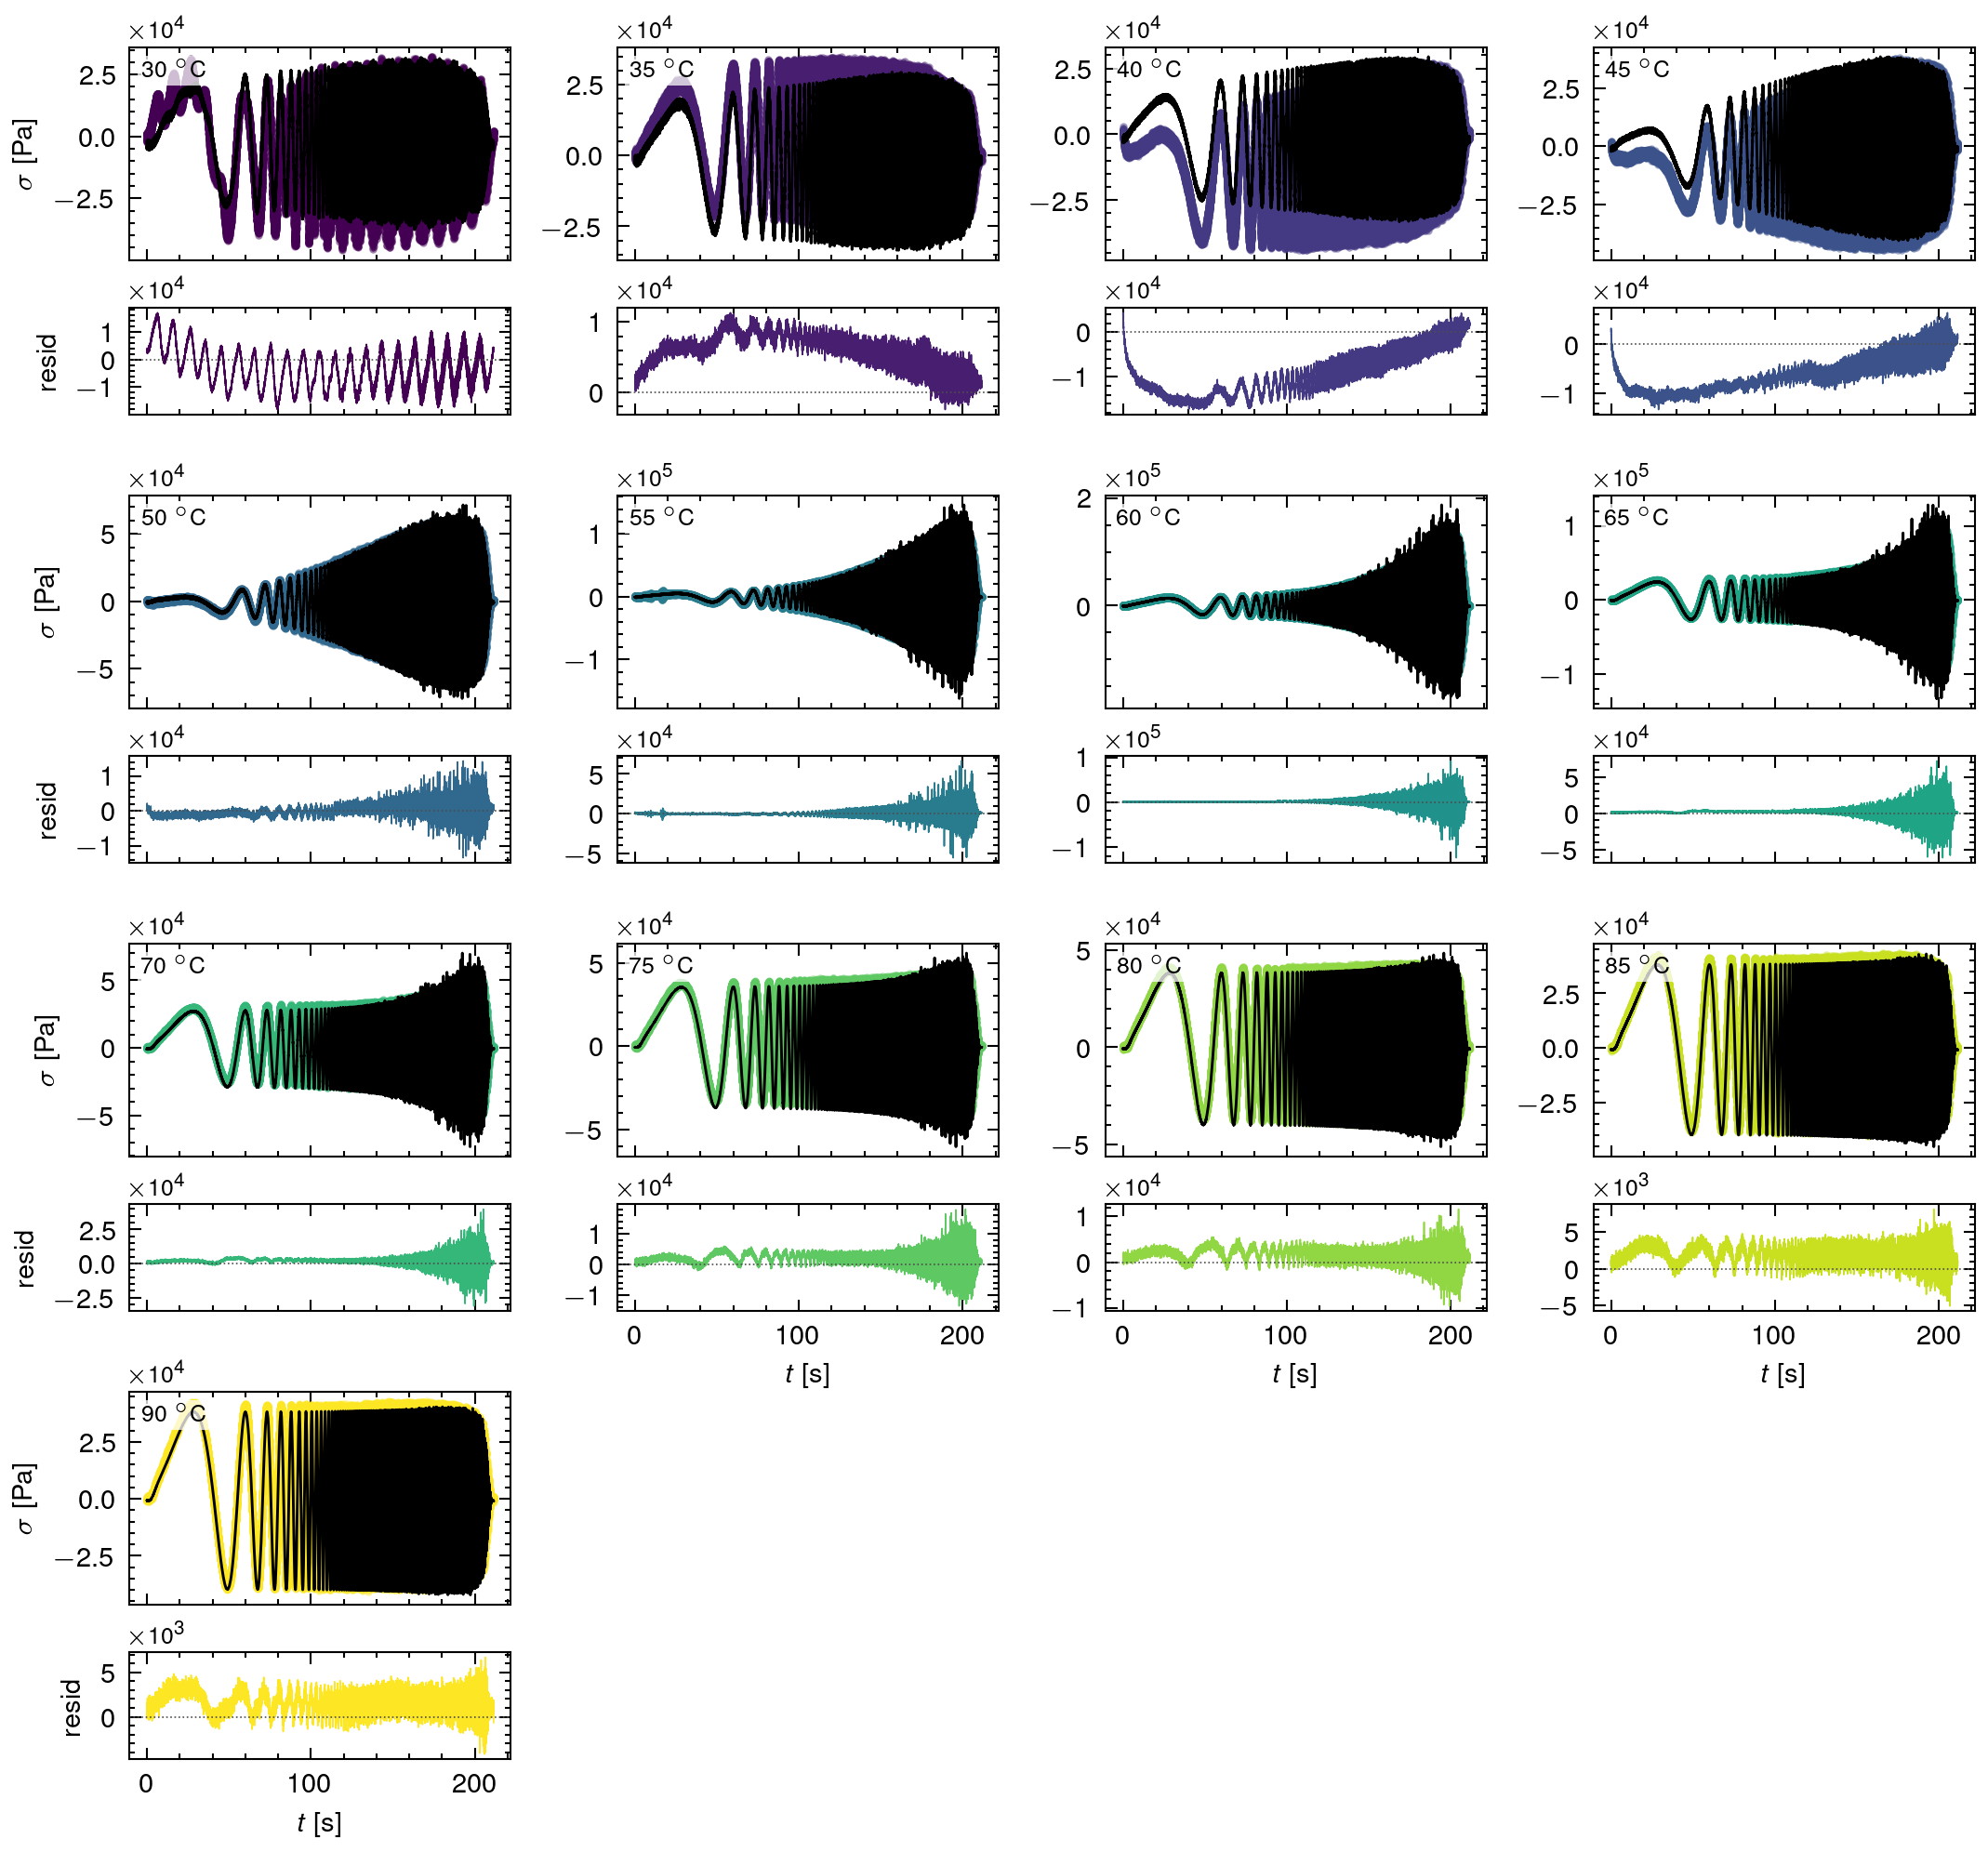

In [20]:
"""
plot_residuals_per_chirp.py
============================
Per-record (fit, residual) panels for every temperature in an
`export_master_curve()` bundle -- one fit+residual pair per chirp,
laid out on the SAME fixed-width (two-column, 7.0in) canvas as every
other figure in this notebook, so text reads at the identical size
once every figure is placed in the paper, regardless of how many
panels a given figure holds. No import of `paper_utils`, `rheogp`, or
`torch` -- copy this next to your exported data and run it.

Same visual language as the master-curve figure: the model's own
prediction always plotted in black, measured data colored by its own
record's temperature (continuous viridis, same identity convention as
elsewhere), each panel's sci-notation y-offset kept independent
(`use_sci_y`) since a residual band and a raw stress axis can be
orders of magnitude apart. No figure/axes titles -- which temperature
a panel belongs to is an in-axes text label, not a title; a caption
belongs in the paper, not the image.

Layout note: constrained_layout is turned OFF for this specific figure
(overriding this notebook's usual default). With a grid-of-grids this
deep -- one nested fit+residual pair per record, tiled across a big
outer grid -- constrained_layout's automatic margin solver inflates
the gap BETWEEN records to several times the gap WITHIN a record's own
fit+residual pair, regardless of the hspace values actually asked for
(verified: swapping hspace or even disabling constrained_layout via
the `plt.figure(constrained_layout=...)` keyword left the rendered gap
unchanged -- only overriding the `figure.constrained_layout.use` rcParam
directly, before the figure is created, actually turns it off). Doing
the margins by hand via plain GridSpec fractions instead gives direct,
predictable control: tight within a record, modestly larger between
records.

Edit EXPORT_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize

# Where the fitting notebook (and run_broadband_demo.py) wrote their
# outputs. Every input below is read from this one folder; figures
# this cell writes go to FIG_DIR.
DATA_DIR = "pt_fzm_out"
EXPORT_PATH = f"{DATA_DIR}/PT_export_fzm"      # base path -> reads fmm_export.npz + fmm_export.json
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "pt_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/PT_residuals_per_chirp"
NCOLS = 4                      # same panel count/row as Copy1's per-record figure
TEMP_CMAP = "viridis"


def load_export(path):
    from types import SimpleNamespace
    with open(f"{path}.json") as fh:
        meta = json.load(fh)
    data = np.load(f"{path}.npz")
    arrays = {k: data[k] for k in data.files}

    def record(i):
        pfx = f"rec{i}_"
        return {k[len(pfx):]: v for k, v in arrays.items() if k.startswith(pfx)}

    return SimpleNamespace(meta=meta, arrays=arrays, record=record,
                            n_records=meta["n_records"])


try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})

COLOR_PRED = "black"  # model prediction -- fixed, not per-record, matches
                       # the master-curve figure's own convention


def use_sci_y(ax, fontsize=6):
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
    ax.yaxis.get_offset_text().set_fontsize(fontsize)


data = load_export(EXPORT_PATH)
T = np.asarray(data.arrays["temperatures"], float)
n_rec = data.n_records

temp_cmap = plt.get_cmap(TEMP_CMAP)
temp_norm = Normalize(vmin=float(T.min()), vmax=float(T.max()))


def record_color(i):
    return temp_cmap(temp_norm(T[i]))


nrows = int(np.ceil(n_rec / NCOLS))

# last populated row for each column -- since records fill row-major and
# the final row can be partial, a column's actual bottom panel is not
# always in row (nrows - 1)
last_row_for_col = {}
for i in range(n_rec):
    r, c = divmod(i, NCOLS)
    last_row_for_col[c] = max(last_row_for_col.get(c, -1), r)

# constrained_layout OFF just for this figure -- see module docstring.
plt.rcParams["figure.constrained_layout.use"] = False
fig = plt.figure(figsize=(7.0, 1.65 * nrows))
outer = gridspec.GridSpec(nrows, NCOLS, figure=fig, wspace=0.28, hspace=0.22,
                           left=0.05, right=0.995, top=0.98, bottom=0.05)

for i in range(n_rec):
    r, c = divmod(i, NCOLS)
    inner = gridspec.GridSpecFromSubplotSpec(
        2, 1, subplot_spec=outer[r, c], height_ratios=[2.0, 1.0], hspace=0.3)
    ax_fit = fig.add_subplot(inner[0])
    ax_res = fig.add_subplot(inner[1], sharex=ax_fit)

    rec = data.record(i)
    col = record_color(i)
    resid = rec["sigma"] - rec["pred"]

    ax_fit.plot(rec["t"], rec["sigma"], color=col, lw=0.0, marker="o", ms=1.0, alpha=0.5)
    ax_fit.plot(rec["t"], rec["pred"], color=COLOR_PRED, lw=0.7)
    ax_fit.text(0.03, 0.94, f"${T[i]:g}~^\\circ\\mathrm{{C}}$", transform=ax_fit.transAxes,
                fontsize=6, ha="left", va="top",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.0))
    ax_fit.tick_params(labelbottom=False)
    use_sci_y(ax_fit)
    if c == 0:
        ax_fit.set_ylabel(r"$\sigma$ [Pa]")

    ax_res.plot(rec["t"], resid, color=col, lw=0.4)
    ax_res.axhline(0, color="0.3", lw=0.4, ls=":")
    ax_res.tick_params()
    use_sci_y(ax_res)
    if c == 0:
        ax_res.set_ylabel("resid")
    if r == last_row_for_col[c]:
        ax_res.set_xlabel(r"$t$ [s]")
    else:
        ax_res.tick_params(labelbottom=False)

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display
    display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)


FractionalZenerS: ran 5120 epochs
wrote pt_figures/PT_convergence.pdf and pt_figures/PT_convergence.png


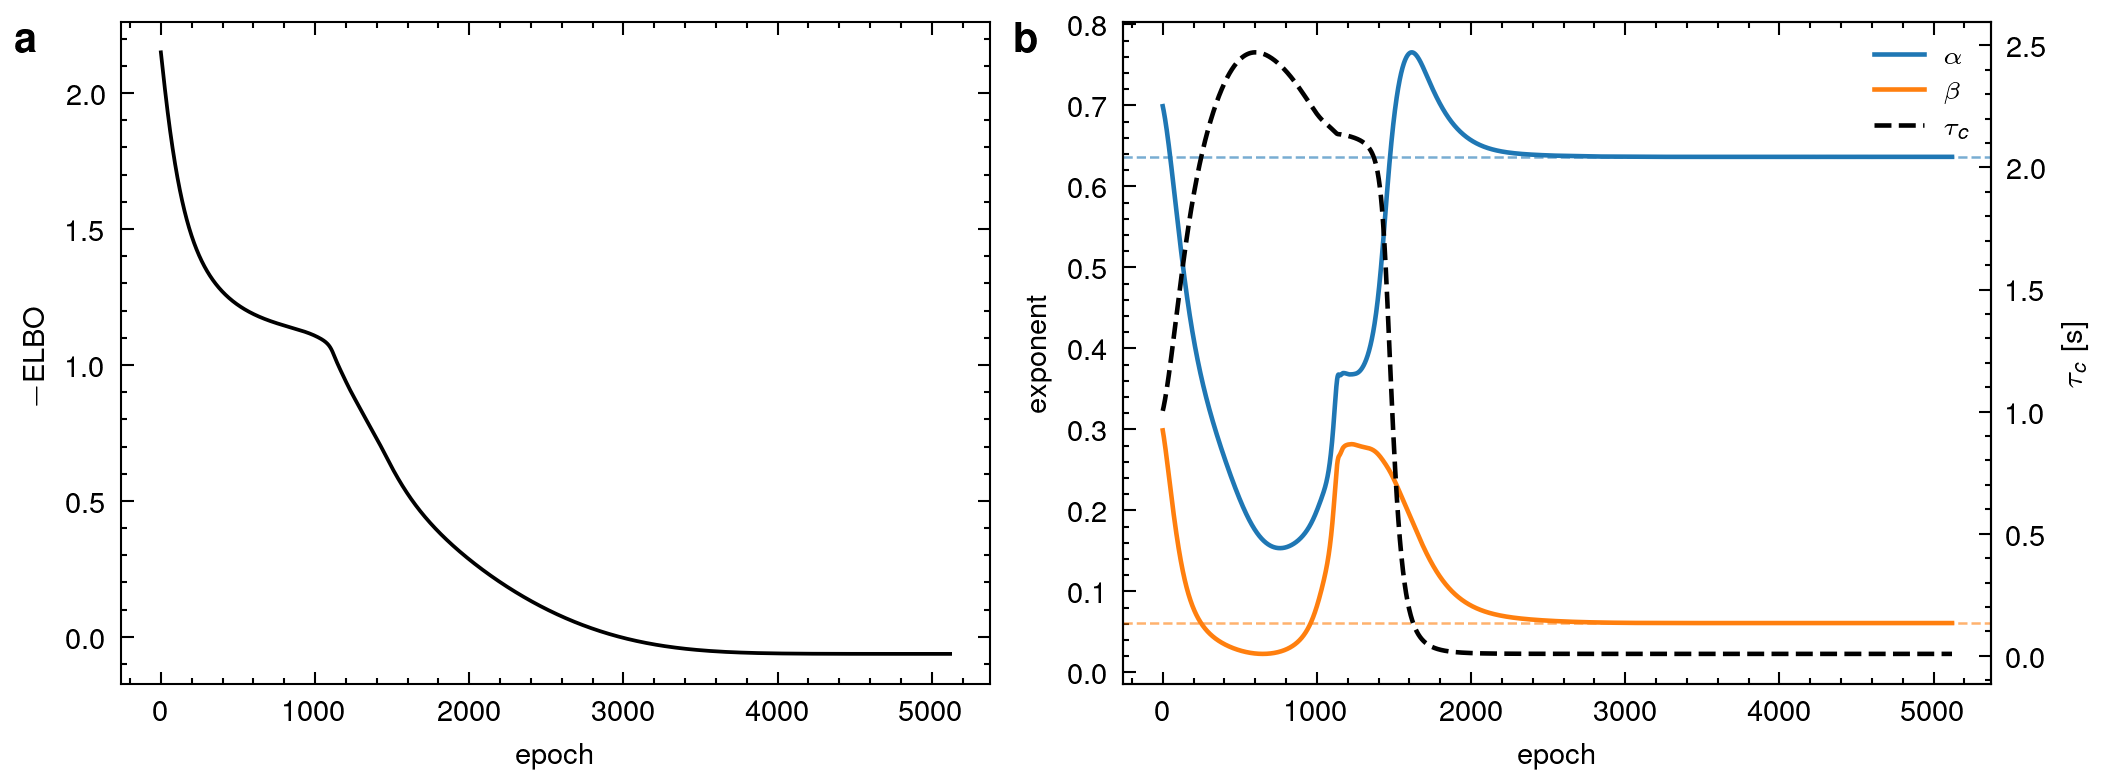

In [21]:
"""
plot_convergence.py
====================
Training-convergence figure from an `export_master_curve()` bundle's
`hist_loss` / `hist_param_*` arrays -- the same quantities
`SPGP.plot_convergence()` reads from `history_`, replotted at this
notebook's own fixed two-column width (7.0in) and font sizes so it
sits next to every other figure without a font-size mismatch. No
import of `paper_utils`, `rheogp`, or `torch`.

Left: training loss (-ELBO, lower is better) vs. epoch. Right: every
shared shape parameter vs. epoch, alpha/beta/kappa on the primary axis
(dimensionless exponents), tau_c on its own secondary axis (its own
units/scale) -- same layout convention as `rheogp.plots.plot_convergence`.

Edit EXPORT_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# Where the fitting notebook (and run_broadband_demo.py) wrote their
# outputs. Every input below is read from this one folder; figures
# this cell writes go to FIG_DIR.
DATA_DIR = "pt_fzm_out"
EXPORT_PATH = f"{DATA_DIR}/PT_export_fzm"      # base path -> reads fmm_export.npz + fmm_export.json
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "pt_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/PT_convergence"

with open(f"{EXPORT_PATH}.json") as fh:
    meta = json.load(fh)
data = np.load(f"{EXPORT_PATH}.npz")

try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})


def add_panel_letter(ax, text, xoff=-20, yoff=0, fontsize=10):
    ax.annotate(
        text, xy=(0, 1), xycoords="axes fraction",
        xytext=(xoff, yoff), textcoords="offset points",
        ha="right", va="top",
        fontsize=fontsize, fontweight="bold",
        clip_on=False, zorder=100,
    )


loss = data["hist_loss"]
param_names = [k[len("hist_param_"):] for k in data.files if k.startswith("hist_param_")]
params = {k: data[f"hist_param_{k}"] for k in param_names}
n_epochs_ran = len(loss)

PARAM_COLORS = {"alpha": "tab:blue", "beta": "tab:orange", "kappa": "tab:green"}
PARAM_LABELS = {"alpha": r"$\alpha$", "beta": r"$\beta$", "kappa": r"$\nu$"}  # kappa is labeled nu in the plot, per convention
TAU_COLOR = "black"

fig, (ax_loss, ax_par) = plt.subplots(1, 2, figsize=(7.0, 2.6))

ax_loss.plot(loss, lw=0.9, color="k")
ax_loss.set_xlabel("epoch")
ax_loss.set_ylabel(r"$-\mathrm{ELBO}$")
add_panel_letter(ax_loss, r"$\mathbf{a}$")

ax_par_r = ax_par.twinx()
lines, labels = [], []
for name, vals in params.items():
    if name == "tau_c":
        continue
    c = PARAM_COLORS.get(name, "0.3")
    h, = ax_par.plot(vals, lw=1.1, color=c)
    ax_par.axhline(vals[-1], color=c, lw=0.6, ls="--", alpha=0.6)
    lines.append(h); labels.append(PARAM_LABELS.get(name, f"${name}$"))
if "tau_c" in params:
    h_tau, = ax_par_r.plot(params["tau_c"], lw=1.1, ls="--", color=TAU_COLOR)
    ax_par_r.set_ylabel(r"$\tau_c$ [s]", color=TAU_COLOR, fontsize=7)
    ax_par_r.tick_params(axis="y", colors=TAU_COLOR, labelsize=7)
    lines.append(h_tau); labels.append(r"$\tau_c$")

ax_par.set_xlabel("epoch")
ax_par.set_ylabel("exponent")
ax_par.legend(lines, labels, frameon=False, loc="best", fontsize=6)
add_panel_letter(ax_par, r"$\mathbf{b}$")

n_budget = meta.get("n_epochs_budget", None)
tag = f"{meta['model_name']}: ran {n_epochs_ran} epochs"
if n_budget:
    tag += f"/{n_budget}"
print(tag)

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display
    display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)


FractionalZenerS
   T [C]    tau_int          N      N_eff
      30      373.7      21345       57.1
      35     4143.6      21150        5.1
      40     5347.4      21151        4.0
      45     5259.8      21151        4.0
      50     1391.0      21151       15.2
      55        2.7      21150     7718.8
      60        1.0      21150    21150.0
      65        1.0      21150    21150.0
      70        1.0      21150    21150.0
      75      113.0      21151      187.3
      80      224.7      21151       94.1
      85      219.9      21150       96.2
      90      368.9      21150       57.3
pooled: N=275150, N_eff=71689.1, mean tau_int=1342.1
wrote pt_figures/PT_residual_autocorr.pdf and pt_figures/PT_residual_autocorr.png


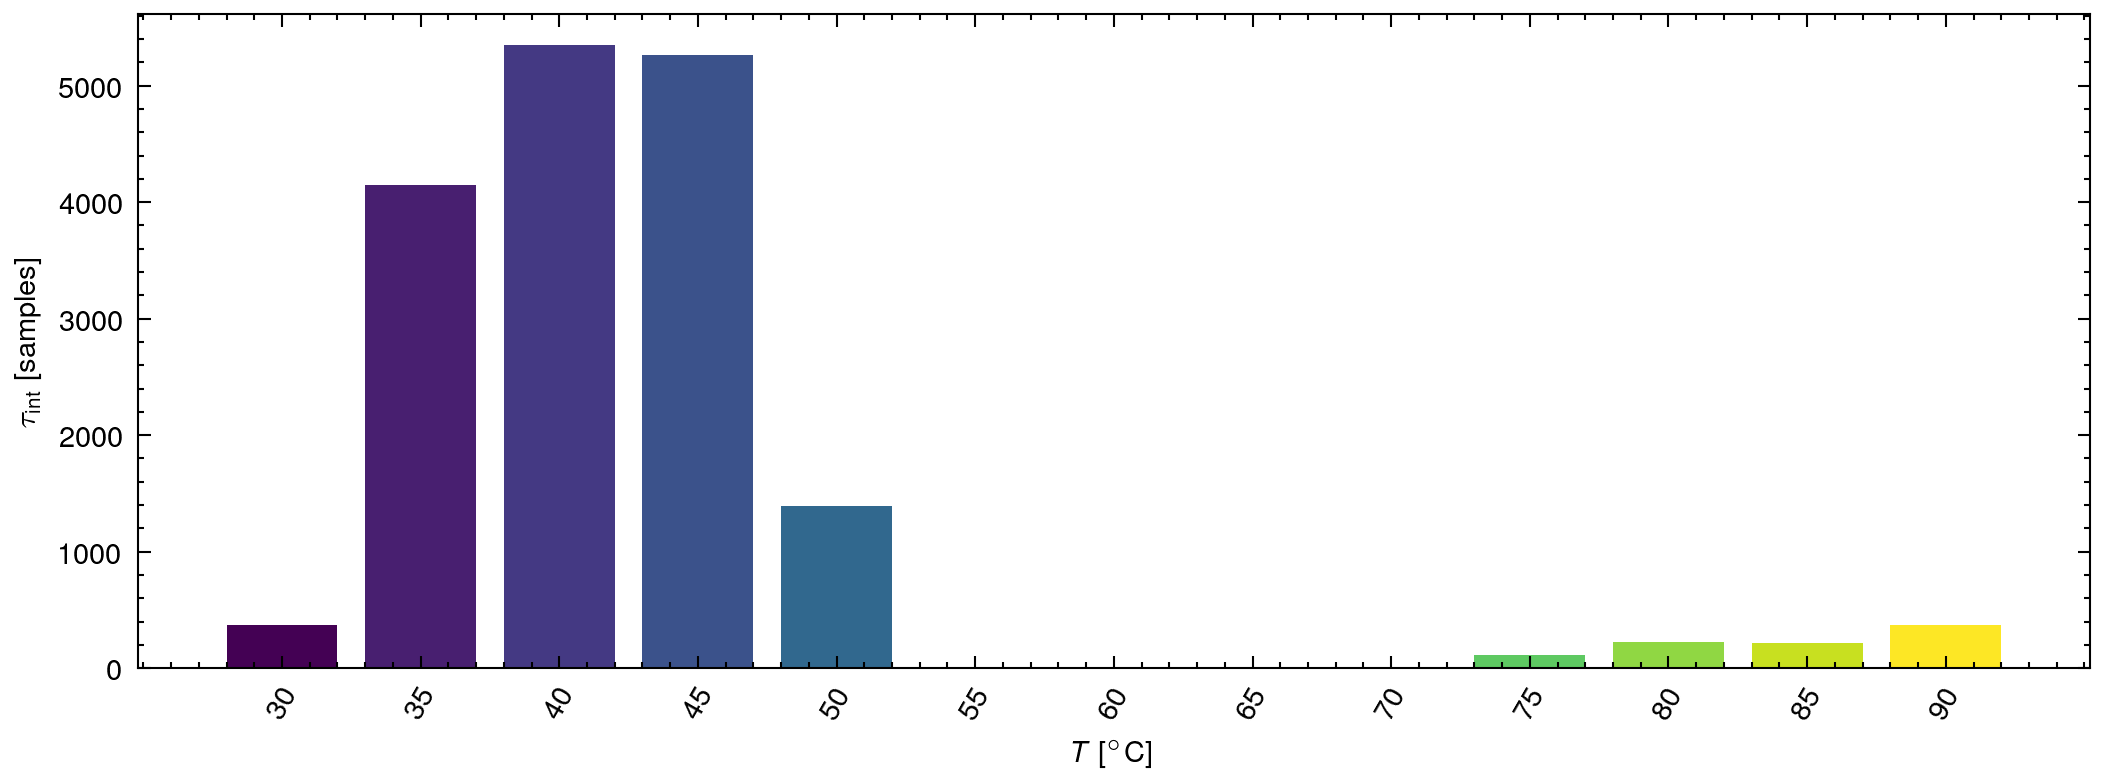

In [22]:
"""
plot_residual_autocorrelation.py
=================================
Residual integrated-autocorrelation-time (tau_int) per record, from an
`export_master_curve()` bundle, at this notebook's fixed two-column
width (7.0in) / font sizes. No import of `paper_utils`, `rheogp`, or
`torch`: `integrated_autocorr_time` below is a pure-numpy
re-implementation of `rheogp.utils.integrated_autocorr_time` (FFT
autocorrelation + Geyer's initial-positive-sequence rule, Sokal 1989 --
the same estimator emcee/ArviZ use for MCMC chains), applied to each
record's own residual (sigma - pred) since autocorrelation only means
something WITHIN one chirp, never across the concatenated multi-record
vector.

Edit EXPORT_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Where the fitting notebook (and run_broadband_demo.py) wrote their
# outputs. Every input below is read from this one folder; figures
# this cell writes go to FIG_DIR.
DATA_DIR = "pt_fzm_out"
EXPORT_PATH = f"{DATA_DIR}/PT_export_fzm"      # base path -> reads fmm_export.npz + fmm_export.json
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "pt_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/PT_residual_autocorr"
TEMP_CMAP = "viridis"


def _acf(x, nlags=None):
    """Normalised autocorrelation function via FFT (zero-padded to
    avoid circular wrap-around), rho[0] == 1."""
    x = np.asarray(x, float)
    x = x - x.mean()
    n = x.size
    if n < 2:
        return np.array([1.0])
    if nlags is None:
        nlags = min(n - 1, 5000)
    nfft = 1 << int(np.ceil(np.log2(2 * n)))
    f = np.fft.rfft(x, nfft)
    r = np.fft.irfft(f * np.conjugate(f), nfft)[:nlags + 1].real
    return r / r[0] if r[0] > 0 else np.zeros_like(r)


def integrated_autocorr_time(x, nlags=5000):
    """tau_int = 1 + 2*sum_k rho_k via Geyer's initial-positive-sequence
    rule: accumulate consecutive lag PAIRS while their sum stays
    positive. Returns tau_int >= 1.0."""
    x = np.asarray(x, float)
    n = x.size
    if n < 4:
        return 1.0
    rho = _acf(x, nlags=min(nlags, n - 1))
    s, k = 0.0, 1
    while k + 1 < rho.size:
        pair = rho[k] + rho[k + 1]
        if pair <= 0:
            break
        s += pair
        k += 2
    return float(max(1.0 + 2.0 * s, 1.0))


with open(f"{EXPORT_PATH}.json") as fh:
    meta = json.load(fh)
data = np.load(f"{EXPORT_PATH}.npz")
T = np.asarray(data["temperatures"], float)
n_rec = int(meta["n_records"])

try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 6,
    "axes.grid": False,
    "figure.constrained_layout.use": True,
})

temp_cmap = plt.get_cmap(TEMP_CMAP)
temp_norm = Normalize(vmin=float(T.min()), vmax=float(T.max()))

tau_int = np.empty(n_rec)
n_raw = np.empty(n_rec, dtype=int)
for i in range(n_rec):
    resid = data[f"rec{i}_sigma"] - data[f"rec{i}_pred"]
    tau_int[i] = integrated_autocorr_time(resid)
    n_raw[i] = resid.size

n_eff = n_raw / tau_int
print(f"{meta['model_name']}")
print(f"{'T [C]':>8} {'tau_int':>10} {'N':>10} {'N_eff':>10}")
for i in range(n_rec):
    print(f"{T[i]:>8g} {tau_int[i]:>10.1f} {n_raw[i]:>10d} {n_eff[i]:>10.1f}")
print(f"pooled: N={n_raw.sum()}, N_eff={n_eff.sum():.1f}, mean tau_int={tau_int.mean():.1f}")

fig, ax = plt.subplots(figsize=(7.0, 2.6))

bar_colors = [temp_cmap(temp_norm(t)) for t in T]
ax.bar(range(n_rec), tau_int, color=bar_colors)
ax.set_xticks(range(n_rec))
ax.set_xticklabels([f"{t:g}" for t in T], rotation=60)
ax.set_xlabel(r"$T~[^\circ\mathrm{C}]$")
ax.set_ylabel(r"$\tau_{\mathrm{int}}$ [samples]")

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display
    display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)


In [23]:
"""
plot_broadband_chirp_demo.py
=============================
"One huge chirp instead of TTS" self-consistency check, from the
`PT_broadband_demo.npz`/.json bundle written alongside the
regular `export_master_curve()` export (see notebook 035's section
"3c)" for the full derivation). No import of `paper_utils`, `rheogp`,
or `torch` -- pure numpy/json, same standalone-script convention as
this notebook's other figures, at the SAME fixed two-column width
(7.0in) and font sizes.

Layout mirrors the master-curve figure's own column split: LEFT column
stacks the synthetic broadband chirp's input strain and the stress
response the WINNING model's own physics predicts for it (a forward
simulation through the analytic Gstar transfer function -- not a
regression fit to anything, so there is nothing else to overlay on
it) on a shared time axis; RIGHT panel overlays that single-chirp
G'/G'' reconstruction on the REAL 13-chirp data, shaded over the
frequency range the single chirp can actually reach.

The right panel deliberately matches the master-curve figure's own
spectrum-panel convention instead of the smooth analytic curve used
earlier: the 13-chirp side is the ACTUAL per-record FFT points (from
the main `export_master_curve()` bundle, `EXPORT_PATH`), colored by
temperature on the same continuous viridis scale (filled marker = G',
open marker = G''); the single-broadband-chirp side is that record's
own G'/G'' reconstruction (from the fresh single-record regression
`run_broadband_demo.py` fit to it -- the self-consistency check itself:
can one chirp's own regression recover the same physics the 13-chirp
joint fit found?) drawn as scattered squares, same filled/open =
G'/G'' convention, in one fixed color so it reads as a single series
against the temperature-colored real data underneath it.

The bundle comes from run_broadband_demo.py, which is set up for the
DGEBA data; point its DATA_DIR / EXPORT_PATH / OUT_PATH at
pt_fzm_out/PT_export_fzm and PT_broadband_demo to
generate it. Until then this cell prints a note and skips.

Edit EXPORT_PATH / DEMO_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize

# Where the fitting notebook (and run_broadband_demo.py) wrote their
# outputs. Every input below is read from this one folder; figures
# this cell writes go to FIG_DIR.
DATA_DIR = "pt_fzm_out"
EXPORT_PATH = f"{DATA_DIR}/PT_export_fzm"      # base path -> reads fmm_export.npz + fmm_export.json
DEMO_PATH = f"{DATA_DIR}/PT_broadband_demo"   # the single-chirp self-consistency bundle
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "pt_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/PT_broadband_demo"
DOWNSAMPLE = 8            # stride for the time-domain panels (display only --
                          # the full raw chirp renders far more slowly/heavily
                          # than a PDF needs to show the envelope)
TEMP_CMAP = "viridis"

if not (os.path.exists(f"{DEMO_PATH}.json") and os.path.exists(f"{DEMO_PATH}.npz")):
    print(f"skipped: {DEMO_PATH}.json/.npz not found -- run run_broadband_demo.py "
          "against the PT export first (see docstring)")
else:
    with open(f"{DEMO_PATH}.json") as fh:
        meta = json.load(fh)
    data = np.load(f"{DEMO_PATH}.npz")
    with open(f"{EXPORT_PATH}.json") as fh:
        export_meta = json.load(fh)
    export = np.load(f"{EXPORT_PATH}.npz")
    T = np.asarray(export["temperatures"], float)
    n_rec = int(export_meta["n_records"])

    try:
        import scienceplots  # noqa: F401
        plt.style.use(["science", "nature", "bright"])
    except ImportError:
        print("scienceplots not found -- falling back to default matplotlib style "
              "(install with `pip install scienceplots` to match the paper exactly)")

    plt.rcParams.update({
        "axes.labelsize": 7,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 6,
        "axes.grid": False,
        "figure.constrained_layout.use": True,
    })

    COLOR_INPUT = "tab:blue"     # single fixed color -- one record, no T-colormap needed
    COLOR_PRED = "black"         # model prediction -- fixed, matches every other figure
    COLOR_DEMO = "black"         # single-broadband-chirp G'/G'' markers

    temp_cmap = plt.get_cmap(TEMP_CMAP)
    temp_norm = Normalize(vmin=float(T.min()), vmax=float(T.max()))


    def record_color(i):
        return temp_cmap(temp_norm(T[i]))


    def add_panel_letter(ax, text, xoff=-20, yoff=0, fontsize=10):
        ax.annotate(
            text, xy=(0, 1), xycoords="axes fraction",
            xytext=(xoff, yoff), textcoords="offset points",
            ha="right", va="top",
            fontsize=fontsize, fontweight="bold",
            clip_on=False, zorder=100,
        )


    def use_sci_y(ax, fontsize=6):
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)
        ax.yaxis.get_offset_text().set_fontsize(fontsize)


    t = data["t_demo"][::DOWNSAMPLE]
    strain = data["strain_demo"][::DOWNSAMPLE]
    stress = data["stress_demo"][::DOWNSAMPLE]

    fig = plt.figure(figsize=(7.0, 3.0))
    outer = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.0, 1.25], wspace=0.28)
    gs_left = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[0], hspace=0.1)
    ax_strain = fig.add_subplot(gs_left[0])
    ax_stress = fig.add_subplot(gs_left[1], sharex=ax_strain)
    ax_spec = fig.add_subplot(outer[1])

    # -- left, top: input chirp --------------------------------------------
    ax_strain.plot(t, strain, color=COLOR_INPUT, lw=0.5)
    ax_strain.set_ylabel(r"$\gamma(t)$")
    ax_strain.tick_params(labelbottom=False)
    use_sci_y(ax_strain)
    add_panel_letter(ax_strain, r"$\mathbf{a}$", yoff=2)

    # -- left, bottom: stress response THE MODEL PREDICTS for that input --
    # a direct forward simulation through the fitted physics' analytic
    # Gstar (plus the same small observation-noise level used elsewhere in
    # this notebook) -- a single deterministic curve, not a fit to
    # anything, so there is no separate "prediction" line to overlay on it.
    ax_stress.plot(t, stress, color=COLOR_PRED, lw=0.6)
    ax_stress.set_ylabel(r"$\sigma(t)$ [Pa]")
    ax_stress.set_xlabel(r"$t$ [s]")
    use_sci_y(ax_stress)
    add_panel_letter(ax_stress, r"$\mathbf{b}$", yoff=2)

    # -- right: real 13-chirp data (scattered, colored by T) vs. the single
    # broadband chirp's own G'/G'' (scattered squares, one fixed color) --
    # filled marker = G', open marker = G'' in both series, same convention
    # as the master-curve figure's own spectrum panels.
    for i in range(n_rec):
        c = record_color(i)
        om_r = export[f"rec{i}_fft_omega_reduced"]
        ax_spec.loglog(om_r, export[f"rec{i}_fft_Gp"], marker="o", ms=2.2,
                       ls="none", mfc=c, mec=c, alpha=0.6)
        ax_spec.loglog(om_r, export[f"rec{i}_fft_Gdp"], marker="o", ms=2.2,
                       ls="none", mfc="none", mec=c, alpha=0.6)

    omega_d, Gp_d, Gdp_d = data["omega_demo"], data["Gp_demo"], data["Gdp_demo"]
    h_gp, = ax_spec.loglog(omega_d, Gp_d, marker="s", ms=3.2, ls="none",
                            mfc=COLOR_DEMO, markevery=0.01, mec=COLOR_DEMO)
    h_gdp, = ax_spec.loglog(omega_d, Gdp_d, marker="s", ms=3.2, ls="none",
                             mfc="none", markevery=0.01, mec=COLOR_DEMO)
    ax_spec.axvspan(meta["demo_lo"], meta["demo_hi"], color="0.5", alpha=0.10)

    ax_spec.set_xlabel(r"$\omega~[\mathrm{rad~s}^{-1}]$")
    ax_spec.set_ylabel(r"$G',\,G''$ [Pa]")
    ax_spec.legend(
        [h_gp, h_gdp, plt.matplotlib.patches.Patch(facecolor="0.5", alpha=0.10)],
        ["$G'$ -- single broadband chirp", "$G''$ -- single broadband chirp",
         "single-chirp coverage"],
        frameon=False, fontsize=5.5, loc="best")
    add_panel_letter(ax_spec, r"$\mathbf{c}$")

    sm = plt.cm.ScalarMappable(norm=temp_norm, cmap=temp_cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax_spec, pad=0.02, aspect=30, fraction=0.05)
    cbar.set_label(r"$T~[^\circ\mathrm{C}]$", fontsize=6.5)
    cbar.ax.tick_params(labelsize=6)

    print(f"single {meta['N_DEMO']:,.0f}-sample chirp ({meta['n_decades_demo']:.1f} decades) "
          f"vs. {n_rec}-chirp master curve ({meta['n_decades_full']:.1f} decades)")

    fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
    fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
    print(f"wrote {OUT_NAME}.pdf and {OUT_NAME}.png")
    try:
        from IPython.display import Image, display
        display(Image(filename=f"{OUT_NAME}.png"))
    except ImportError:
        pass
    plt.close(fig)


skipped: pt_fzm_out/PT_broadband_demo.json/.npz not found -- run run_broadband_demo.py against the PT export first (see docstring)


dataset            : PT
candidates fitted  : FZS
N (pooled samples) : 275150
BIC resolution floor = 2*N*patience_tol = 55.0 units -- gaps below this are optimiser slop, not evidence.

NOTE: only ONE candidate (FZS) was fitted, so there is nothing to select between.
      Uncomment more entries in CANDIDATE_MODELS in the fitting notebook and re-run to get a real comparison.

     model    k      N_eff  tau_int        bic_raw    bic_eff_pen   bic_eff_full   noise sd   epochs
----------------------------------------------------------------------------------------------------
       FZS   21    71689.1   1342.1           0.00           0.00           0.00       6185     5120

winner by criterion: bic_raw -> FZS, bic_eff_pen -> FZS, bic_eff_full -> FZS

wrote pt_figures/PT_model_selection.pdf and pt_figures/PT_model_selection.png


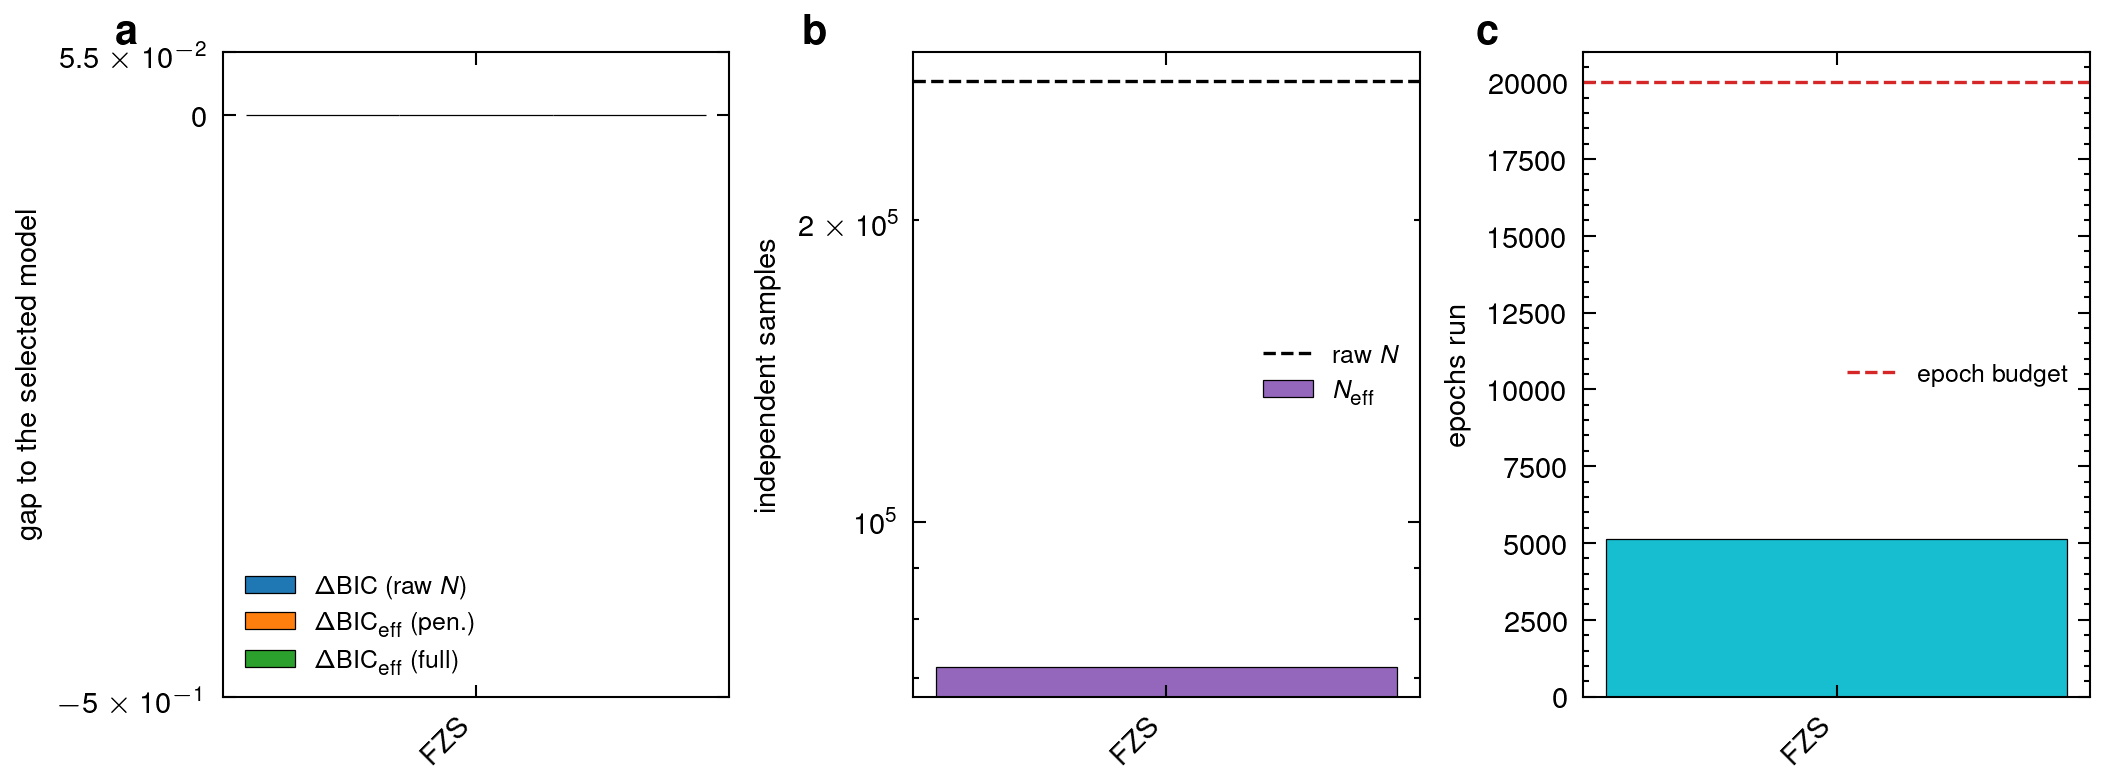

In [24]:
"""
plot_model_selection_real.py
=============================
Which constitutive law the information criteria select on the REAL
dataset, from the `export_model_comparison()` bundle the fitting notebook
writes (`pt_fzm_out/PT_model_comparison.json`). Pure numpy + json + matplotlib --
no `rheogp`, no `torch` -- at this notebook's fixed two-column width
(7.0in) and font sizes.

This is the real-data counterpart of the synthetic notebook's
noise-sweep selection figure. What does NOT carry over from that one:
there is no injected noise to sweep and no ground truth to score
against, so parameter-recovery-vs-noise and inferred-vs-true-noise have
no meaning here. What replaces them is the question that does have
meaning on real data -- is the winning margin larger than the numerical
resolution of the fits that produced it?

  (a) each candidate's gap to the winner under AIC, BIC on the raw N,
      and both N_eff-corrected BIC conventions, with the resolution
      floor shaded.
  (b) how much INDEPENDENT evidence backs each fit: N_eff against the
      raw N. Adjacent residuals in a chirp sampled far above the
      material's own bandwidth are nearly the same number repeated, so
      N overstates the evidence and the k*ln(N) penalty is too harsh.
  (c) where each fit stopped. A candidate that hit its epoch budget has
      provisional criteria; one that early-stopped well short of a
      rival's epoch count may simply have stopped at a worse ELBO,
      which shows up as a BIC gap that is optimiser slop, not evidence.

Edit CMP_PATH / OUT_NAME and run.
"""
import os
import json
import numpy as np
import matplotlib.pyplot as plt

# Where the fitting notebook (and run_broadband_demo.py) wrote their
# outputs. Every input below is read from this one folder; figures
# this cell writes go to FIG_DIR.
DATA_DIR = "pt_fzm_out"
CMP_PATH = f"{DATA_DIR}/PT_model_comparison"
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "pt_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_NAME = f"{FIG_DIR}/PT_model_selection"
# AIC dropped from the figure and the tables -- still computed and still
# in the exported bundle, just not shown.
PANEL_CRITERIA = ["bic_raw", "bic_eff_pen", "bic_eff_full"]
PATIENCE_TOL = 1e-4        # the fits' own `patience_tol` (SPGP default).
                           # Early stopping accepts any epoch improving the
                           # per-point ELBO by less than this, so two
                           # candidates can differ by up to ~2*N*tol in
                           # -2logL purely from where their optimisers
                           # stopped. That is a RESOLUTION FLOOR on every
                           # criterion here: a gap below it is slop, not
                           # evidence. Lower it (and raise `patience`) in
                           # the fitting notebook's FITKW to push the floor down.

CRIT_LABEL = {"aic": r"$\Delta\mathrm{AIC}$",
              "bic_raw": r"$\Delta\mathrm{BIC}$ (raw $N$)",
              "bic_eff_pen": r"$\Delta\mathrm{BIC}_{\mathrm{eff}}$ (pen.)",
              "bic_eff_full": r"$\Delta\mathrm{BIC}_{\mathrm{eff}}$ (full)"}
DISPLAY = {"FractionalMaxwell": "FMM", "FractionalMaxwellGel": "FMG",
           "FractionalMaxwellLiquid": "FML", "Maxwell": "Maxwell",
           "FractionalZener": "FZ", "FractionalZenerS": "FZS",
           "FractionalZenerSolidS": "FZSS", "FractionalZenerLiquidS": "FZLS",
           "FractionalZenerLiquidD": "FZLD", "Zener": "Zener",
           "FractionalKelvinVoigt": "FKV", "FractionalKelvinVoigtS": "FKVS",
           "FractionalKelvinVoigtD": "FKVD", "SpringPot": "SpringPot"}

with open(f"{CMP_PATH}.json") as fh:
    b = json.load(fh)

res = b["candidate_results"]
delta = b["delta"]
winners = b["winners"]
names = sorted(res, key=lambda n: res[n]["bic_raw"])
disp = [DISPLAY.get(n, n) for n in names]
N = int(res[names[0]]["n_data"])
floor = 2.0 * N * PATIENCE_TOL

try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "nature", "bright"])
except ImportError:
    print("scienceplots not found -- falling back to default matplotlib style "
          "(install with `pip install scienceplots` to match the paper exactly)")

plt.rcParams.update({
    "axes.labelsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7,
    "legend.fontsize": 6, "axes.grid": False,
    "figure.constrained_layout.use": True,
})


def add_panel_letter(ax, text, xoff=-20, yoff=9, fontsize=10):
    ax.annotate(text, xy=(0, 1), xycoords="axes fraction",
                xytext=(xoff, yoff), textcoords="offset points",
                ha="right", va="top", fontsize=fontsize, fontweight="bold",
                clip_on=False, zorder=100)


print(f"dataset            : {b.get('dataset', '?')}")
print(f"candidates fitted  : {', '.join(disp)}")
print(f"N (pooled samples) : {N}")
print(f"BIC resolution floor = 2*N*patience_tol = {floor:.1f} units -- "
      "gaps below this are optimiser slop, not evidence.\n")

if len(names) == 1:
    print(f"NOTE: only ONE candidate ({disp[0]}) was fitted, so there is "
          "nothing to select between.\n      Uncomment more entries in "
          "CANDIDATE_MODELS in the fitting notebook and re-run to get a real "
          "comparison.\n")

fig, (axA, axB, axC) = plt.subplots(1, 3, figsize=(7.0, 2.6))
x = np.arange(len(names))
w = 0.8 / len(PANEL_CRITERIA)
COLORS = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

for j, crit in enumerate(PANEL_CRITERIA):
    vals = np.array([delta[crit][n] for n in names], float)
    axA.bar(x + (j - (len(PANEL_CRITERIA) - 1) / 2) * w, vals, w,
            color=COLORS[j % len(COLORS)], edgecolor="k", linewidth=0.3,
            label=CRIT_LABEL.get(crit, crit))
# The resolution floor is reported in the printout below rather than
# shaded on the axes -- the band competed with the data it qualified.
axA.set_yscale("symlog", linthresh=1.0)
axA.set_ylim(bottom=-0.5)
axA.set_xticks(x); axA.set_xticklabels(disp, rotation=45, ha="right")
axA.set_ylabel("gap to the selected model")
axA.legend(frameon=False, loc="best")
add_panel_letter(axA, r"$\mathbf{a}$")

n_eff = np.array([res[n]["n_eff"] for n in names], float)
axB.bar(x, n_eff, 0.55, color="tab:purple", edgecolor="k", linewidth=0.3,
        label=r"$N_{\mathrm{eff}}$")
axB.axhline(N, color="k", ls="--", lw=0.8, label=r"raw $N$")
axB.set_yscale("log")
axB.set_xticks(x); axB.set_xticklabels(disp, rotation=45, ha="right")
axB.set_ylabel("independent samples")
axB.legend(frameon=False, loc="best")
add_panel_letter(axB, r"$\mathbf{b}$")

ran = np.array([res[n]["n_epochs_ran"] for n in names], float)
budget = res[names[0]].get("n_epochs_budget")
axC.bar(x, ran, 0.55, color="tab:cyan", edgecolor="k", linewidth=0.3)
if budget:
    axC.axhline(budget, color="tab:red", ls="--", lw=0.8, label="epoch budget")
    axC.legend(frameon=False, loc="best")
axC.set_xticks(x); axC.set_xticklabels(disp, rotation=45, ha="right")
axC.set_ylabel("epochs run")
add_panel_letter(axC, r"$\mathbf{c}$")

hdr = (f"{'model':>10} {'k':>4} {'N_eff':>10} {'tau_int':>8} "
       + " ".join(f"{c:>14}" for c in PANEL_CRITERIA)
       + f" {'noise sd':>10} {'epochs':>8}")
print(hdr); print("-" * len(hdr))
for n, d_ in zip(names, disp):
    c = res[n]
    print(f"{d_:>10} {c['k']:>4} {c['n_eff']:>10.1f} {c['mean_tau_int']:>8.1f} "
          + " ".join(f"{delta[cr][n]:>14.2f}" for cr in PANEL_CRITERIA)
          + f" {c['noise_sd_inferred']:>10.4g} {c['n_epochs_ran']:>8d}")

print(f"\nwinner by criterion: "
      + ", ".join(f"{cr} -> {DISPLAY.get(winners[cr], winners[cr])}"
                  for cr in PANEL_CRITERIA))
if len(names) > 1:
    margin = delta["bic_raw"][names[1]]
    verdict = ("RESOLVED" if margin > floor else
               "NOT RESOLVED -- the gap is within optimiser slop")
    print(f"BIC(raw) margin over the runner-up: {margin:.2f} "
          f"vs floor {floor:.1f}  ->  {verdict}")
    if any(c.get("early_stopped") is False for c in res.values()):
        hit = [DISPLAY.get(n, n) for n in names
               if res[n].get("early_stopped") is False]
        print(f"WARNING: {', '.join(hit)} hit the epoch budget -- "
              "their criteria are provisional.")

fig.savefig(f"{OUT_NAME}.pdf", bbox_inches="tight")
fig.savefig(f"{OUT_NAME}.png", dpi=300, bbox_inches="tight")
print(f"\nwrote {OUT_NAME}.pdf and {OUT_NAME}.png")
try:
    from IPython.display import Image, display
    display(Image(filename=f"{OUT_NAME}.png"))
except ImportError:
    pass
plt.close(fig)

In [25]:
"""
run_mastercurve_comparison.py
==============================
Build the SAME master curve a second way -- with the `mastercurves`
package (Lennon, McKinley & Swan, PNAS 2023) instead of rheogp's joint
fit -- and fit both with `pyRheo`, so the two routes can be compared
end to end. Writes one `<CMP_PATH>.json`/`.npz` bundle; the cell after
this one plots it and needs neither package.

The two routes are genuinely independent. rheogp infers a_T as fitted
parameters of one constitutive model applied jointly to every chirp:
shifts and physics come out together. `mastercurves` superposes the
data with Gaussian process regression and maximum a posteriori
estimation and assumes no constitutive model at all, so a_T is its
only output. Agreement is evidence for both; disagreement says the
superposition step is where they part.

What is superposed
------------------
SHIFT_KIND selects the curve handed to `mastercurves`. The default is
**tan(delta) = G''/G'**, which is invariant to any vertical shift b_T,
so superposing it horizontally recovers a_T without vertical-shift
contamination; "gstar" superposes |G*| instead, which carries the
modulus scale and therefore assumes b_T = 1 unless VERTICAL is on.
Either way the a_T that comes out is then applied to G' AND G'' to
build the master curve -- the shifted quantity is only the vehicle for
finding the shifts.

Requires `pip install mastercurves pyRheo` (only this cell does; the
plotting cell below is pure numpy/json). The RAW FFT spectra go to the
package as-is -- every point, unbinned, and for |G*| with nothing
filtered out, since |G*| is positive by construction and needs no
positivity cut before its logarithm.
"""
import numpy as np

# Re-read mastercurve_compare.py on every run; see the plotting cell.
import importlib
import mastercurve_compare
importlib.reload(mastercurve_compare)

from mastercurve_compare import (
    spectra_for_superposition, run_mastercurves, overlap_report,
    build_master_curve_raw, align_reference, fit_pyrheo,
    fmm_quasiproperties,
    export_mastercurve_comparison,
)

# ---------------------------- USER SETTINGS ----------------------------
# Where the fitting notebook (and run_broadband_demo.py) wrote their
# outputs. Every input below is read from this one folder; figures
# this cell writes go to FIG_DIR.
DATA_DIR = "pt_fzm_out"
EXPORT_PATH = f"{DATA_DIR}/PT_export_fzm"     # the export_master_curve() bundle to re-shift
CMP_PATH = f"{DATA_DIR}/PT_mccompare"           # written: <CMP_PATH>.json + <CMP_PATH>.npz
SHIFT_KIND = "gstar"           # what gets superposed to FIND a_T:
                               #   "gstar"    |G*| = sqrt(G'^2 + G''^2)
                               #   "tandelta" G''/G'
                               #   "gp"/"gdp" G' or G'' alone
                               # a_T is then applied to G' AND G'' either way
                               # -- the superposed quantity is only the vehicle
                               # for finding the shifts. Note |G*| carries the
                               # modulus scale, so shifting it horizontally
                               # alone assumes b_T = 1; tan(delta) is immune to
                               # b_T, so it is the safer cross-check if the two
                               # disagree. Set VERTICAL=True to fit b_T too.
VERTICAL = False               # also fit a vertical shift b_T
N_BINS = "auto"                # Binning applies ONLY to finding a_T. The
                               # mastercurves GP is exact per state and goes
                               # singular on a dense linearly-spaced omega grid
                               # (on the raw DGEBA spectra in fzm_dgeba it emitted 11472
                               # overflow warnings and its a_T came out ~0.5
                               # decades WORSE), so "auto" keeps the most
                               # points per state that stay well-conditioned.
                               # The DATA PRESENTED is never binned: the master
                               # curves below are built by build_master_curve_raw()
                               # from every raw FFT point, with these a_T applied.
                               # None forces the raw (ill-conditioned) fit; an
                               # integer forces a specific binning.
# Independently reported shift factors, used as a third baseline both
# routes are measured against. None are published for this PT
# dataset, so the comparison is rheogp vs. mastercurves only. To add
# one, set the label and fill in matching temperatures [C] and a_T.
REPORTED_LABEL = None
REPORTED_TEMPS = None
REPORTED_AT = None
PYRHEO_MODEL = None            # None -> the bundle's own model_name
PYRHEO_KW = dict(initial_guesses="random", num_initial_guesses=64,
                 minimization_algorithm="Powell")
# -----------------------------------------------------------------------

spec, values, qlabel = spectra_for_superposition(
    EXPORT_PATH, shift_kind=SHIFT_KIND, n_bins=N_BINS)
print(f"{EXPORT_PATH}: {len(spec['omega'])} records, "
      f"T = {spec['temps'].min():g}..{spec['temps'].max():g} C, "
      f"reference T = {spec['T_ref']:g} C, model = {spec['model_name']}")
# raw -> positive (G' and G'' both > 0, needed before taking logs) ->
# used. Printed per record so any thinning is visible, never silent.
print(f"{'T [C]':>7} {'raw':>6} {'positive':>9} {'used':>6}")
for T, (n_raw, n_pos, n_use) in zip(spec["temps"], spec["point_counts"]):
    flag = "  <- binned" if n_use < n_pos else ""
    print(f"{T:>7g} {n_raw:>6d} {n_pos:>9d} {n_use:>6d}{flag}")

print(f"\nsuperposing {SHIFT_KIND} horizontally"
      + (" and vertically" if VERTICAL else "")
      + f" across {len(spec['temps'])} temperatures ...")
mcres = run_mastercurves(spec["omega"], values, spec["temps"],
                         spec["i_ref"], vertical=VERTICAL)

# Which states are actually pinned down by overlap, and which are not.
# Pairwise superposition chains its shifts, so a barely-overlapping pair
# leaves its own shift loose and passes that looseness down the chain --
# this says which temperature to distrust when the two routes disagree.
overlap_report(spec["omega"], mcres["aT"], spec["temps"])

# The SAME raw spectra, shifted two different ways. Note these are built
# from the FULL RAW spectra regardless of what N_BINS did above: binning
# (if any) is a numerical requirement of the step that FINDS a_T, not a
# property of the comparison. Once a_T is known it is one number per
# record, and it belongs on every measured point -- which also keeps
# this figure consistent with the master curve plotted elsewhere in this
# notebook from the same export.
curve_ours = build_master_curve_raw(EXPORT_PATH, spec["temps"], spec["aT_rheogp"])
curve_mc = build_master_curve_raw(EXPORT_PATH, spec["temps"], mcres["aT"])

# The same raw spectra a third time, under independently reported shift
# factors -- only when some are given above.
aT_reported = curve_ref = None
if REPORTED_AT is not None:
    aT_reported = align_reference(spec["temps"], REPORTED_TEMPS, REPORTED_AT,
                                  i_ref=spec["i_ref"])
    curve_ref = build_master_curve_raw(EXPORT_PATH, spec["temps"], aT_reported)
print(f"\napplied a_T to G' and G'' -> master curves of "
      f"{curve_ours['omega'].size} points "
      f"(rheogp shifts) and {curve_mc['omega'].size} points "
      f"(mastercurves shifts)")

# The SAME constitutive model fitted to each, by the same package with
# the same settings -- so the parameter gap is attributable to the
# superposition step and nothing else.
model = PYRHEO_MODEL or spec["model_name"]
print(f"\nfitting {model} with pyRheo to the rheogp-shifted master curve ...")
fit_ours = fit_pyrheo(curve_ours["omega"], curve_ours["Gp"], curve_ours["Gdp"],
                      model, **PYRHEO_KW)
print(f"fitting {model} with pyRheo to the mastercurves-shifted master curve ...")
fit_mc = fit_pyrheo(curve_mc["omega"], curve_mc["Gp"], curve_mc["Gdp"],
                    model, **PYRHEO_KW)

# rheogp's own analytic parameters, expressed in pyRheo's
# quasi-property convention -- the reference both fitted columns should
# sit near. Exact only for the Fractional Maxwell family, and the
# conversion self-checks against rheogp's own G*(w) before returning.
extra = {}
if model in ("FractionalMaxwell", "FractionalMaxwellGel"):
    pp = spec["phys_params"]
    gc = spec["prefactors"]["Gc"]["scalar_mean"]
    extra["rheogp_quasiproperties"] = fmm_quasiproperties(
        gc, pp["alpha"], pp.get("beta", 0.0), pp["tau_c"])
    print("\nrheogp's own parameters in pyRheo units: "
          + ", ".join(f"{k}={v:.5g}" for k, v in
                      extra["rheogp_quasiproperties"].items()
                      if isinstance(v, float)))

export_mastercurve_comparison(
    CMP_PATH, spec, mcres, curve_mc, curve_ours, fit_mc, fit_ours,
    shift_kind=SHIFT_KIND, shift_values=values,
    aT_reference=aT_reported, ref_curve=curve_ref,
    reference_label=REPORTED_LABEL or "reported", extra=extra or None,
)

  n_bins= 48 ->  43 points/state: ILL-CONDITIONED (39 numerical warnings)
  n_bins= 40 ->  37 points/state: ILL-CONDITIONED (39 numerical warnings)
  n_bins= 32 ->  30 points/state: well-conditioned
pt_fzm_out/PT_export_fzm: 13 records, T = 30..90 C, reference T = 55 C, model = FractionalZenerS
  T [C]    raw  positive   used
     30   1696      1696     30  <- binned
     35   2289      2289     30  <- binned
     40   1341      1341     30  <- binned
     45   1765      1765     30  <- binned
     50   2385      2385     30  <- binned
     55   2645      2645     30  <- binned
     60   2759      2759     30  <- binned
     65   2853      2853     30  <- binned
     70   2843      2843     30  <- binned
     75   2884      2884     30  <- binned
     80   2845      2845     30  <- binned
     85   2885      2885     30  <- binned
     90   2849      2849     30  <- binned

superposing gstar horizontally across 13 temperatures ...
  states handed to MasterCurve (T [C]): ['30', '35', '

('pt_fzm_out/PT_mccompare.json', 'pt_fzm_out/PT_mccompare.npz')

1) SHIFT FACTORS
   T [C]     aT rheogp   aT mastercurves   log10 ratio
      30    7.8596e+05        8.6975e+17       12.0440
      35    2.1812e+05        1.2328e+13        7.7522
      40        6237.3        9.1116e+11        8.1646
      45        339.99        3.6784e+08        6.0342
      50        14.779             70548        3.6788
      55             1                 1        0.0000
      60       0.10807        8.1113e-06       -4.1246
      65      0.016861        1.2619e-06       -4.1259
      70     0.0036799         2.848e-07       -4.1113
      75     0.0010388        6.4281e-08       -4.2085
      80     0.0003783        2.1049e-08       -4.2546
      85    0.00018175        1.2045e-08       -4.1787
      90    0.00011629        1.2045e-08       -3.9848
RMS disagreement: 5.8300 decades
wrote pt_figures/PT_mc_shift_factors.pdf and pt_figures/PT_mc_shift_factors.png

2) MASTER CURVES
  G': median |mc - ours| = 59.46%, max = 211.04%
  G'': median |mc - ours| = 351.9

{'ours': {'G_p': 277875.1858974066,
  'G': 627747.8340730945,
  'V': 18475593.192083728,
  'alpha': 7.921779752128431e-16,
  'beta': 0.6510720119644248,
  'Cost': 9015.4274861979},
 'mastercurves': {'G_p': 246224.36270302802,
  'G': 1540907.0059349195,
  'V': 18606339.269367635,
  'alpha': 5.347927000758232e-10,
  'beta': 0.21885006942622462,
  'Cost': 21731.896382305582}}

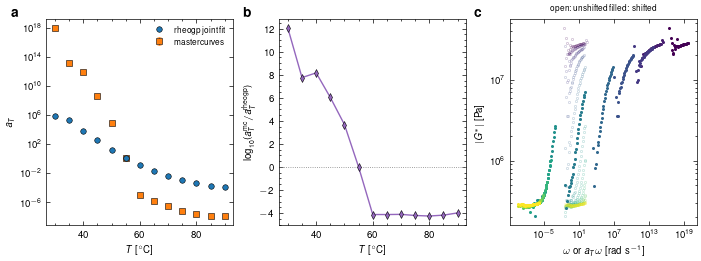

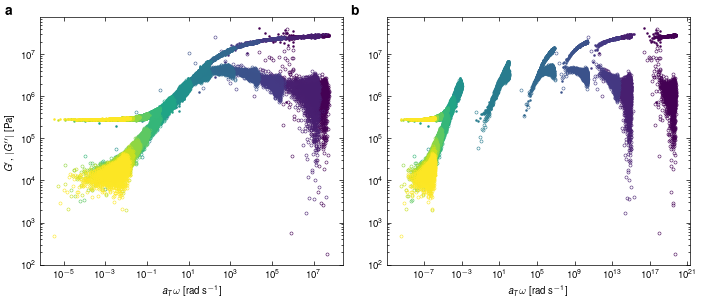

In [26]:
"""
plot_mastercurve_comparison.py
===============================
The three comparison figures, from the `<CMP_PATH>.json`/`.npz` bundle
the cell above writes. Pure numpy + json + matplotlib on this side --
neither `mastercurves` nor `pyRheo` is imported here, so these figures
re-render on any machine that has the bundle.

  1. shift factors   a_T from rheogp's joint fit vs. from the
                     `mastercurves` package (vs. the WLF ground truth,
                     for the synthetic set), their disagreement in
                     decades, and the collapse the package achieved on
                     the quantity it superposed.
  2. master curves   the same raw G'/G'' spectra under each route's own
                     shifts, each with its pyRheo fit, the two fits
                     overlaid, and their relative difference per decade.
  3. parameters      printed as a table, not plotted -- the pyRheo
                     exponents side by side against ground truth,
                     quasi-properties as a ratio, and each fit's own
                     residual, since a parameter gap only means
                     something if both fits describe their data.

Figures are drawn at this notebook's fixed two-column width (7.0in) and
font sizes, like every other figure here.
"""
import os
# Force a re-read of mastercurve_compare.py on every run. Without this,
# a kernel that imported the module earlier in the session keeps serving
# that stale copy, so edits to the figure code (sizes, dpi, panels) never
# reach the output and the cell appears not to have been fixed.
import importlib
import mastercurve_compare
importlib.reload(mastercurve_compare)

from mastercurve_compare import (
    plot_shift_factor_comparison,
    plot_master_curve_comparison,
    print_parameter_comparison,
)

# Where the fitting notebook (and run_broadband_demo.py) wrote their
# outputs. Every input below is read from this one folder; figures
# this cell writes go to FIG_DIR.
DATA_DIR = "pt_fzm_out"
CMP_PATH = f"{DATA_DIR}/PT_mccompare"
# Every figure this notebook writes lands in one folder,
# kept separate from the data folder it reads from.
FIG_DIR = "pt_figures"
os.makedirs(FIG_DIR, exist_ok=True)
OUT_PREFIX = f"{FIG_DIR}/PT_mc"

print("=" * 70, "\n1) SHIFT FACTORS\n" + "=" * 70)
plot_shift_factor_comparison(CMP_PATH, f"{OUT_PREFIX}_shift_factors")

print("\n" + "=" * 70, "\n2) MASTER CURVES\n" + "=" * 70)
plot_master_curve_comparison(CMP_PATH, f"{OUT_PREFIX}_master_curve")

# Printed, not plotted: the pyRheo fits stay in the exported bundle and
# their numbers stay visible here, but nothing about them is drawn.
print("\n" + "=" * 70, "\n3) PARAMETERS (table only)\n" + "=" * 70)
print_parameter_comparison(CMP_PATH)